# Hard & Soft Clustering

**Hard Clustering**: assign each point in a data set to a cluster or to noise, no mixed memberships.

**Soft Clustering**: each point is assigned a i-dimensional vector of probabilities representing how much the point is a member of the i-th cluster. 



https://hdbscan.readthedocs.io/en/latest/soft_clustering.html

In [519]:
# Print CUDA availability
import torch

print('torch.__version__ =', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('Device count:', torch.cuda.device_count())
    try:
        print('Device name:', torch.cuda.get_device_name(0))
    except Exception as e:
        print('Could not get device name:', e)

torch.__version__ = 2.9.1+cu128
CUDA available: True
Device count: 1
Device name: NVIDIA GeForce RTX 3070


## Data preparation

In [520]:
# Import libraries
from sklearn import datasets
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import hdbscan
from hdbscan import all_points_membership_vectors


In [521]:
# Load digits dataset
digits = datasets.load_digits()
data = digits.data
target = digits.target

data, target

(array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
        [ 0.,  0.,  0., ..., 10.,  0.,  0.],
        [ 0.,  0.,  0., ..., 16.,  9.,  0.],
        ...,
        [ 0.,  0.,  1., ...,  6.,  0.,  0.],
        [ 0.,  0.,  2., ..., 12.,  0.,  0.],
        [ 0.,  0., 10., ..., 12.,  1.,  0.]], shape=(1797, 64)),
 array([0, 1, 2, ..., 8, 9, 8], shape=(1797,)))

In [522]:
# Print target distribution
unique, counts = np.unique(target, return_counts=True)

unique, counts

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 array([178, 182, 177, 183, 181, 182, 181, 179, 174, 180]))

In [523]:
# Project data into two dimensions to visualize via t-SNE
projection = TSNE().fit_transform(data)

projection

array([[ -3.0396936, -53.97267  ],
       [ 10.547041 ,  11.315209 ],
       [-13.803058 ,  18.837011 ],
       ...,
       [ -5.368242 ,  10.671186 ],
       [-21.198591 , -15.123936 ],
       [-14.157365 ,   7.0903277]], shape=(1797, 2), dtype=float32)

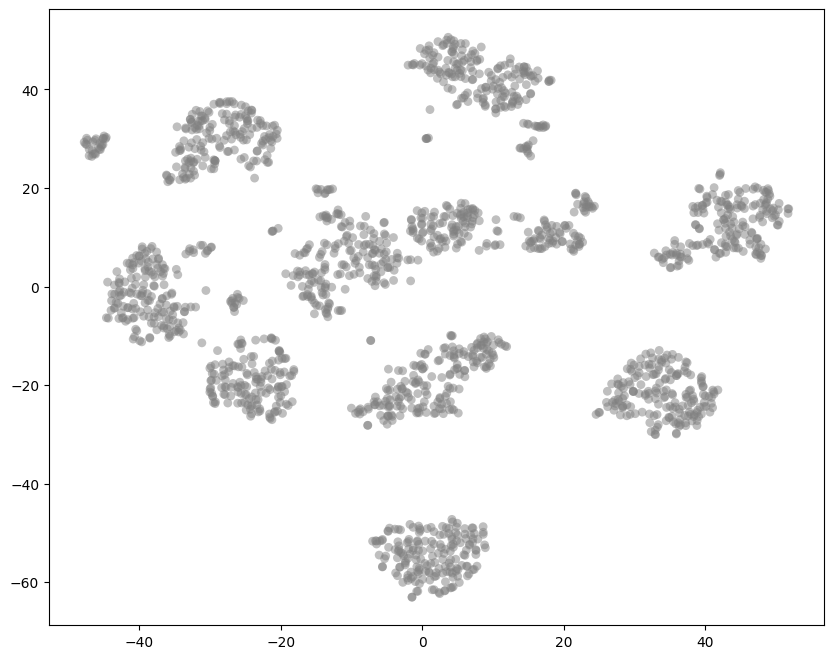

In [524]:
# Plot data in 2-dimensional space
# Plotting arguments: s = marker size, c = color (RGBA array), alpha = transparency
plt.figure(figsize=(10, 8))
plt.scatter(*projection.T, s=40, linewidth=0, color=[0.5, 0.5, 0.5], alpha=0.5, edgecolors='none')
plt.savefig("images/digits_tSNE")

In [525]:
# Define min-max scaling function
def min_max_scale(array):
    return (array - array.min()) / (array.max() - array.min())

## Hard Clustering

In [526]:
# Hard Clustering
hard_clusterer = hdbscan.HDBSCAN(min_cluster_size=10, prediction_data=False).fit(data)

d:\Projects\Thesis\Experiments\.venv\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

d:\Projects\Thesis\Experiments\.venv\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



In [527]:
# Generated labels: numpy ndarray
hard_clusterer.labels_

array([ 2,  9, -1, ..., -1, -1, -1], shape=(1797,))

In [528]:
# Count number of data points in each cluster
hard_clust_dict = dict()

for i in hard_clusterer.labels_:
    if int(i) in hard_clust_dict:
        hard_clust_dict[int(i)] += 1
    else:
        hard_clust_dict[int(i)] = 1

In [529]:
# Show how many clusters are found: -1 represents noise cluster
len(hard_clust_dict.keys())

13

In [530]:
# Show occurrences in each cluster
hard_clust_dict

{2: 172,
 9: 18,
 -1: 839,
 5: 159,
 11: 70,
 3: 131,
 1: 136,
 4: 102,
 8: 68,
 6: 26,
 7: 19,
 10: 37,
 0: 20}

In [531]:
# Sort dictionary by label
sorted_hard_dict = dict(sorted(hard_clust_dict.items(), key=lambda item: item[0])) 

sorted_hard_dict

{-1: 839,
 0: 20,
 1: 136,
 2: 172,
 3: 131,
 4: 102,
 5: 159,
 6: 26,
 7: 19,
 8: 68,
 9: 18,
 10: 37,
 11: 70}

In [532]:
# Show probabilities computed by hard clustering
hard_clusterer.probabilities_

array([0.95807643, 0.95562709, 0.        , ..., 0.        , 0.        ,
       0.        ], shape=(1797,))

In [533]:
print(hard_clusterer.probabilities_.max())

1.0


In [534]:
# Compute mean of non-zero elements in probabilities
arr = np.array(hard_clusterer.probabilities_)
nonzero = arr[arr != 0]
mean_nonzero = nonzero.mean() if nonzero.size > 0 else np.nan
print(mean_nonzero)

0.8852058268344273


In [535]:
# Set colors for hard clusters
hard_color_palette = sns.color_palette('Paired', len(hard_clust_dict.keys())-1)
hard_cluster_colors = [hard_color_palette[x] if x >= 0
                  else (0.5, 0.5, 0.5)
                  for x in hard_clusterer.labels_]
hard_member_colors = [sns.desaturate(x, p) for x, p in
                         zip(hard_cluster_colors, hard_clusterer.probabilities_)]

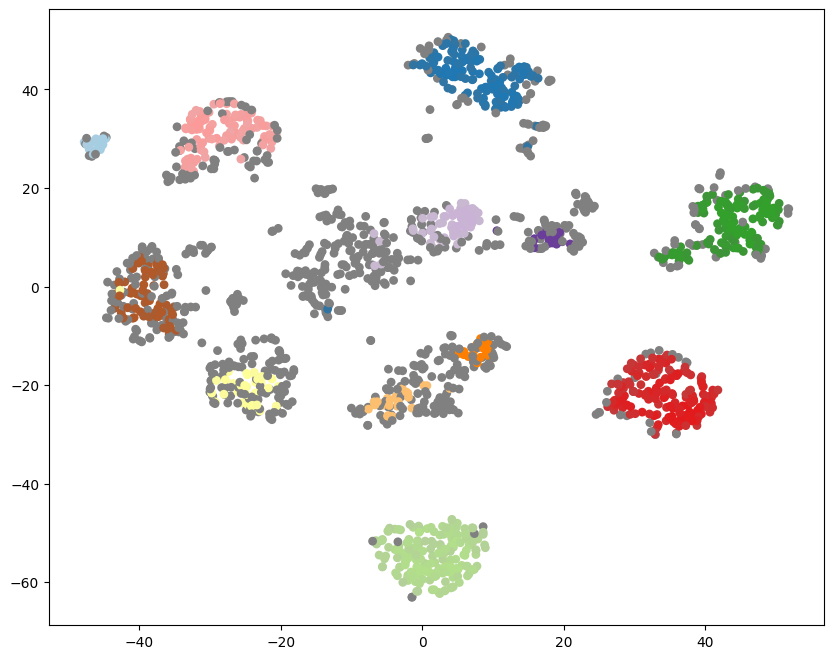

In [536]:
# Plot hard clustering results
plt.figure(figsize=(10, 8))
plt.scatter(*projection.T, s=40, linewidth=0, c=hard_member_colors, edgecolors='none')
plt.savefig("images/hard_clustering_o")

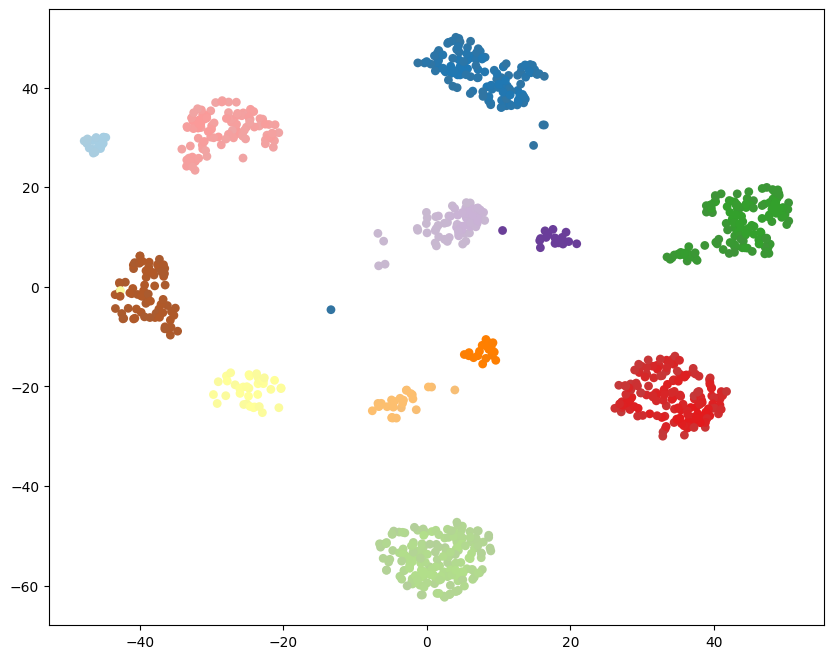

In [537]:
# Exclude noise points for better visualization
mask = np.array(hard_clusterer.labels_) >= 0
proj_masked = projection[mask]
colors_masked = [c for c, m in zip(hard_member_colors, mask) if m]
plt.figure(figsize=(10, 8))
plt.scatter(*proj_masked.T, s=40, linewidth=0, c=colors_masked, edgecolors='none', alpha=1)
plt.savefig("images/hard_clustering")

## Soft Clustering

In [538]:
# Soft Clustering
soft_clusterer = hdbscan.HDBSCAN(min_cluster_size=10, prediction_data=True).fit(data)

d:\Projects\Thesis\Experiments\.venv\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

d:\Projects\Thesis\Experiments\.venv\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



In [539]:
# Generated labels: numpy ndarray
soft_clusterer.labels_

array([ 2,  9, -1, ..., -1, -1, -1], shape=(1797,))

In [540]:
# Count number of data points in each cluster
soft_clust_dict = dict()

for i in soft_clusterer.labels_:
    if int(i) in soft_clust_dict:
        soft_clust_dict[int(i)] += 1
    else:
        soft_clust_dict[int(i)] = 1

In [541]:
# Show occurrences in each cluster
soft_clust_dict

{2: 172,
 9: 18,
 -1: 839,
 5: 159,
 11: 70,
 3: 131,
 1: 136,
 4: 102,
 8: 68,
 6: 26,
 7: 19,
 10: 37,
 0: 20}

In [542]:
# Show probabilities computed by soft clustering
soft_clusterer.probabilities_

array([0.95807643, 0.95562709, 0.        , ..., 0.        , 0.        ,
       0.        ], shape=(1797,))

In [543]:
# Compare probabilities
(hard_clusterer.probabilities_==soft_clusterer.probabilities_).all()

np.True_

In [544]:
# Show soft membership vectors
soft_membership = all_points_membership_vectors(soft_clusterer)

soft_membership

array([[0.05197322, 0.05729871, 0.25788705, ..., 0.05307688, 0.09052542,
        0.06473627],
       [0.0504084 , 0.04686046, 0.03663357, ..., 0.07497948, 0.04353457,
        0.04750335],
       [0.06348371, 0.06868785, 0.06470138, ..., 0.07300455, 0.06140918,
        0.06257285],
       ...,
       [0.06243469, 0.05723128, 0.06028778, ..., 0.06147589, 0.06085098,
        0.05998426],
       [0.05858826, 0.06040728, 0.08056707, ..., 0.07424964, 0.09849795,
        0.08092192],
       [0.06433618, 0.05451673, 0.06513587, ..., 0.05537234, 0.07567997,
        0.0726488 ]], shape=(1797, 12))

In [545]:
# Example of soft membership vector assigned to a data point
soft_membership[1]

array([0.0504084 , 0.04686046, 0.03663357, 0.04938723, 0.047936  ,
       0.04149881, 0.04450181, 0.0470468 , 0.1109248 , 0.07497948,
       0.04353457, 0.04750335])

Label assigned to data point 1000: -1
Original target: 1
Probability: 
0.0
Membership vector: 
[0.14697679 0.05309793 0.05544134 0.05453542 0.07929187 0.06078741
 0.06049863 0.05099277 0.06965635 0.06397926 0.06324328 0.07533284]
Outlier score: 
0.01223507745863571


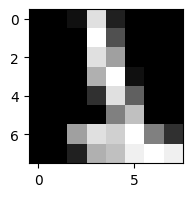

In [546]:
id_data_point = 1000

print("Label assigned to data point " + str(id_data_point) + ": " + str(soft_clusterer.labels_[id_data_point]))
print("Original target: " + str(target[id_data_point]))
plt.figure(figsize = (2,2))
plt.imshow(digits.images[id_data_point], cmap='gray')

print("Probability: ")
print(soft_clusterer.probabilities_[id_data_point])
print("Membership vector: ")
print(soft_membership[id_data_point])
print("Outlier score: ") # Higher -> more likely the point being an outlier
print(soft_clusterer.outlier_scores_[id_data_point])


In [547]:
# Define parameters for visualization
n_points = soft_membership.shape[0]
n_clusters = soft_membership.shape[1]
cols = 2
rows = int(np.ceil(n_clusters / cols))

n_points, n_clusters

(1797, 12)

In [548]:
# Define sharpen factor for visualization
sharpen_factor = 1.0

In [549]:
# Plot soft membership probabilities

def print_soft_membership(rows, cols, n_clusters, projection, sharpen_factor, soft_membership):
    fig, axes = plt.subplots(rows, cols, figsize=(8 * cols, 6 * rows))
    axes = np.array(axes).flatten()

    color_palette = sns.color_palette('Paired', n_clusters)

    for i in range(n_clusters):
        ax = axes[i]
        membership = min_max_scale(soft_membership[:, i])

        base = color_palette[i] if i < len(color_palette) else (0.5, 0.5, 0.5)
        colors = np.zeros((membership.size, 4))
        colors[:, :3] = base
        scaled_mb = min_max_scale(membership ** sharpen_factor)
        colors[:, 3] = scaled_mb

        sc = ax.scatter(*projection.T, s=40, linewidth=0, c=colors, edgecolors='none')
        ax.set_title(f'Cluster {i} membership')

    # Turn off unused subplots
    for j in range(n_clusters, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()


In [550]:
color_palette = sns.color_palette('Paired', n_clusters)

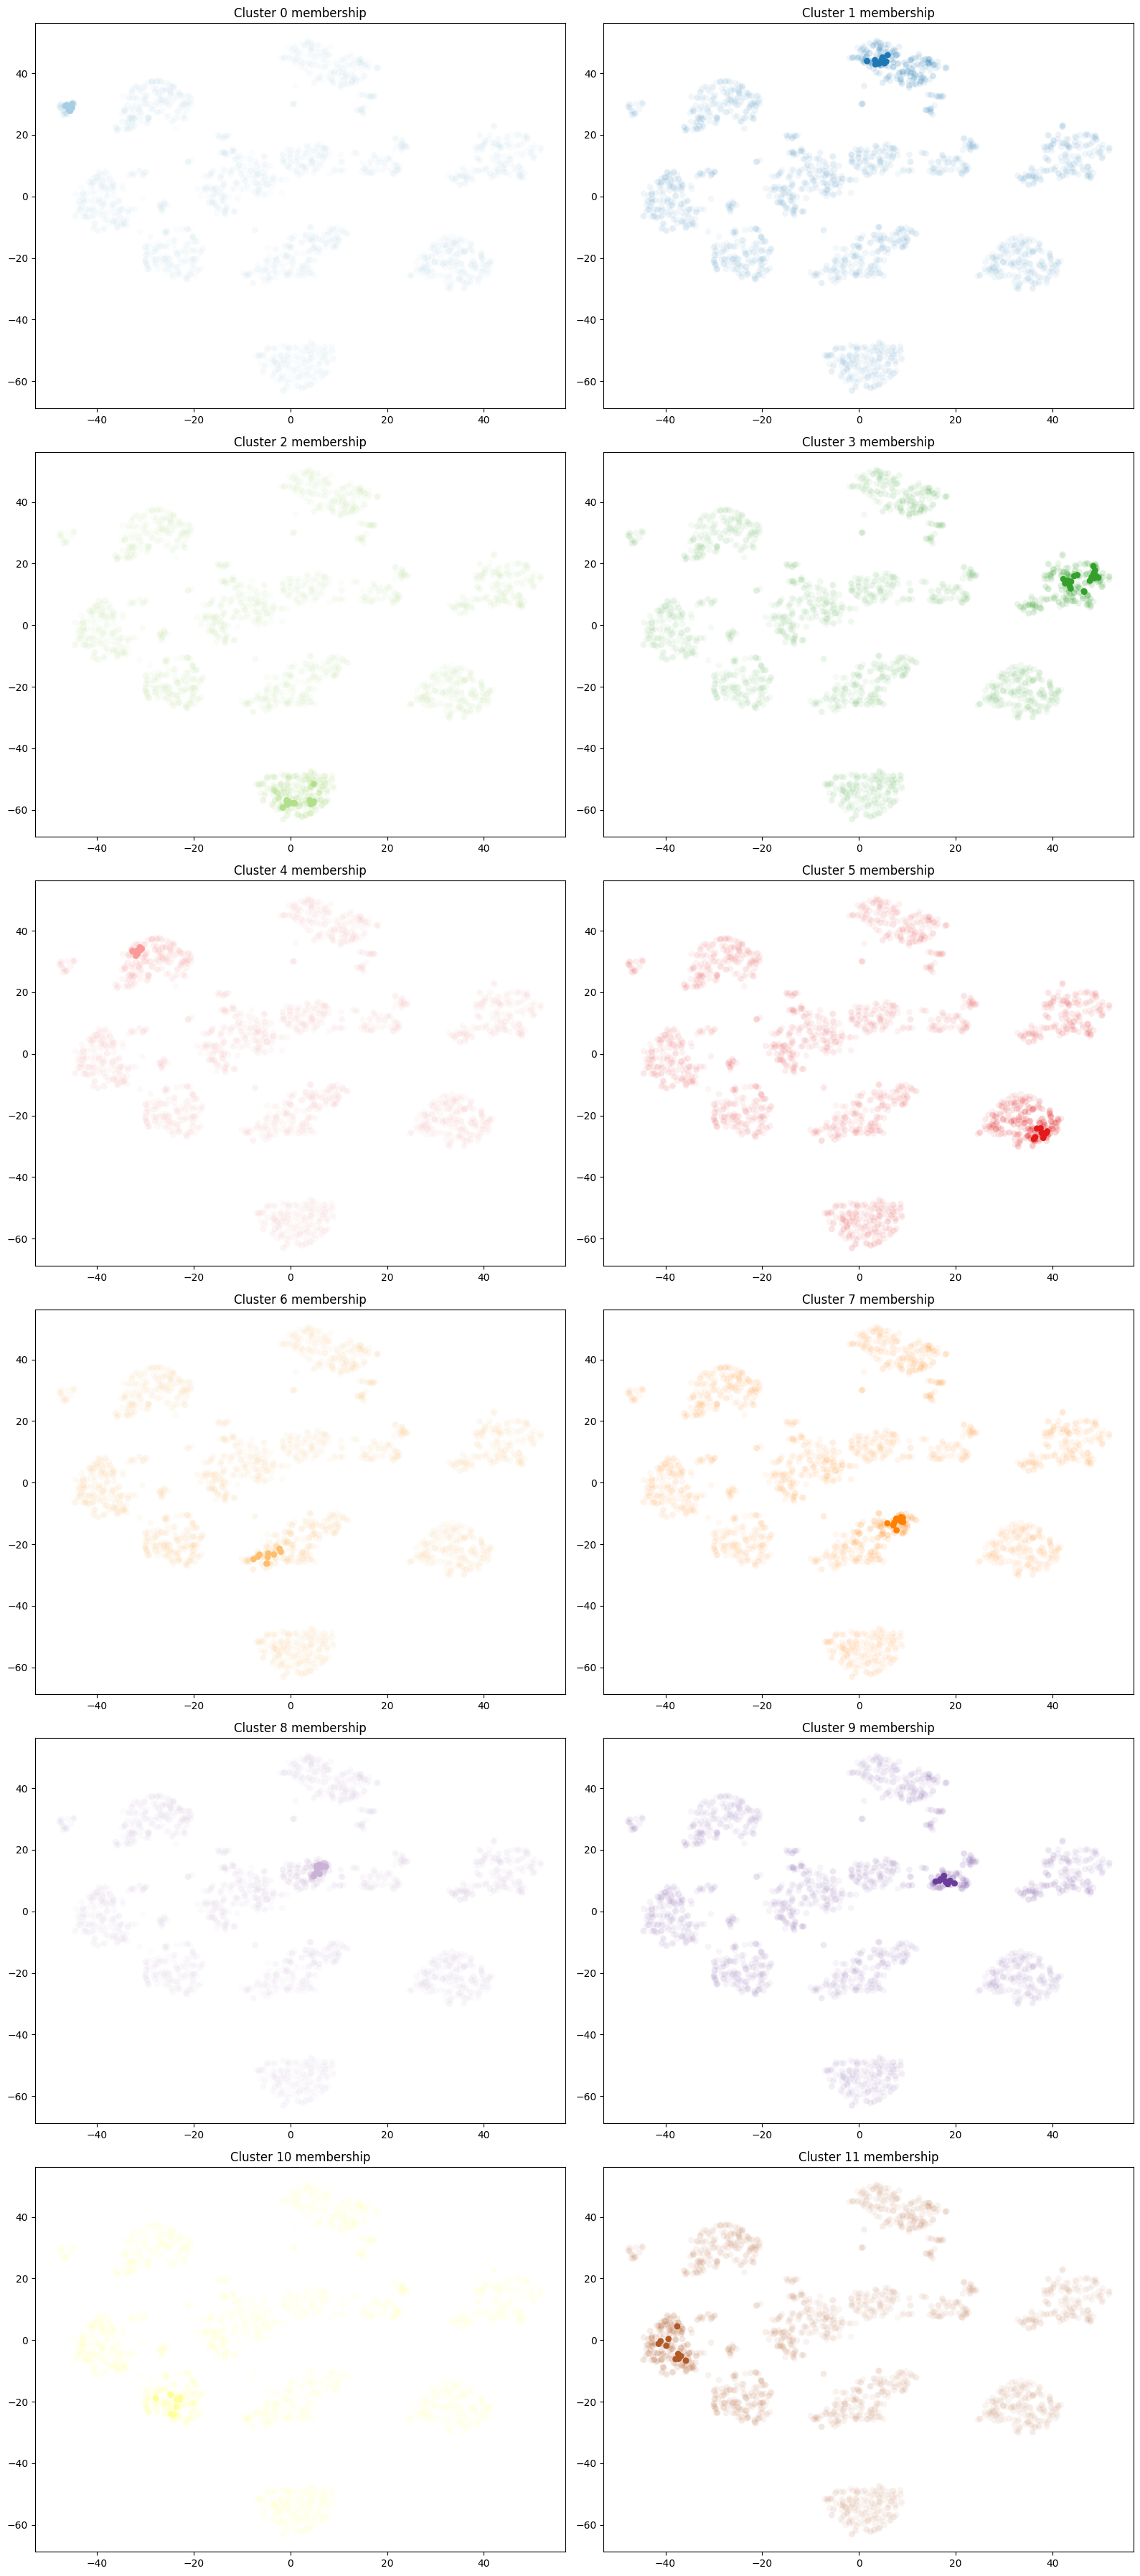

In [551]:
print_soft_membership(rows, cols, n_clusters, projection, sharpen_factor, soft_membership)

### Outlier Distribution

Detection of outliers that may be noticeably different from points in its local region.

https://hdbscan.readthedocs.io/en/latest/outlier_detection.html

C:\Users\zheng\AppData\Local\Temp\ipykernel_37552\329367501.py:2: UserWarning:



`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751




<Axes: ylabel='Density'>

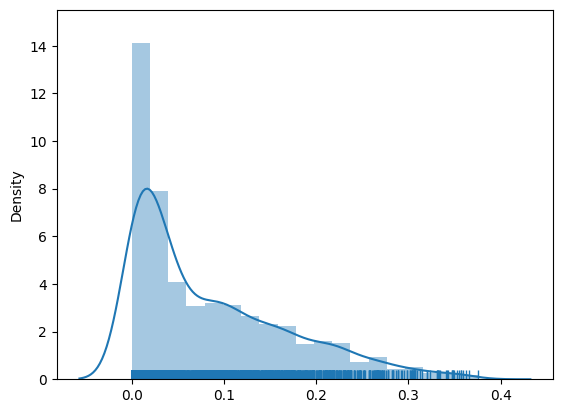

In [552]:
# Plot outlier score distribution
sns.distplot(soft_clusterer.outlier_scores_[np.isfinite(soft_clusterer.outlier_scores_)], rug=True)

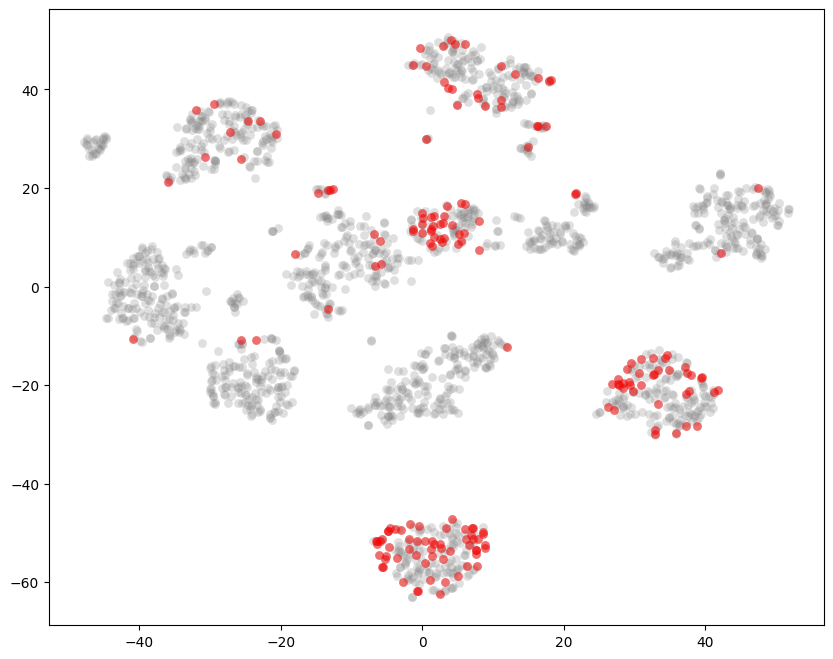

In [553]:
threshold = pd.Series(soft_clusterer.outlier_scores_).quantile(0.9)
outliers = np.where(soft_clusterer.outlier_scores_ > threshold)[0]
plt.figure(figsize=(10, 8))
plt.scatter(*projection.T, s=40, linewidth=0, c='gray', alpha=0.25)
plt.scatter(*projection[outliers].T, s=40, linewidth=0, c='red', alpha=0.5)

# Points at the edge of dense clusters could be highlighted, because they are far enough from the core


### Re-cluster according to membership vectors 

In [554]:
soft_avg = np.average(soft_membership)
print(soft_avg)

0.0699131570108127


In [555]:
soft_threshold = []
add_param = 0.02


for i in range(n_clusters):
    soft_threshold.append(float(np.average(soft_membership[:,i]))+add_param)

soft_threshold

[0.0816185432136879,
 0.0887982586362491,
 0.09587254364382457,
 0.09599310106577384,
 0.0859492812929615,
 0.09097538540179675,
 0.09207521108469698,
 0.08570094135028233,
 0.08924857762480114,
 0.08390316501123102,
 0.09391491906777112,
 0.09490795673667625]

In [556]:
new_labels = []
new_probabilities = []


for i in range(n_points):
    id_max_membership = np.argmax(soft_membership[i])
    if np.max(soft_membership[i]) > soft_threshold[id_max_membership]:
        new_labels.append(int(id_max_membership))
        new_probabilities.append(soft_membership[i][id_max_membership])
    else:
        new_labels.append(-1)
        new_probabilities.append(0)

In [557]:
print(new_labels)
print(len(new_labels))

[2, 8, -1, 11, 3, 10, 5, 1, -1, -1, 2, 9, 4, 11, 3, 7, -1, 1, -1, 10, 2, 9, 4, 11, 3, 7, -1, -1, -1, 10, 2, 10, 6, 6, 5, 7, 2, -1, 7, 10, -1, 3, 9, 1, 1, 11, -1, 9, 2, 2, -1, -1, 1, -1, -1, 2, 9, -1, 5, 11, 11, 1, 11, 11, 3, 5, 5, 5, 3, -1, 9, 6, 2, 10, -1, -1, 8, -1, 2, 2, 9, 1, 5, 11, 4, 9, -1, -1, 5, 11, 9, 11, 10, 8, 1, -1, 7, 3, 11, 8, 3, 2, 6, -1, -1, 10, -1, 9, 1, 7, 3, 3, 1, -1, 8, -1, -1, 7, 1, 10, -1, 3, 8, 8, 3, -1, 2, -1, 10, 8, 2, 9, 4, 11, 3, 7, 5, 1, -1, 10, 2, 9, 4, 11, 3, 7, 5, 1, -1, 10, 2, 9, -1, 11, 3, 7, 5, 1, 8, 10, 2, 10, 7, 7, 5, 7, 2, 10, -1, 10, 8, 8, 9, 1, 1, 11, 7, 9, 2, 2, 4, 4, 1, -1, 4, 2, 9, 4, 5, 11, 11, -1, 11, 11, -1, 5, 5, 5, 8, 10, 9, 7, 2, 10, 7, -1, -1, 4, 2, 2, 9, 1, 5, 11, 4, 9, 1, 11, 9, 11, 10, 9, 1, 5, -1, 3, 11, 9, 3, 2, 7, -1, 5, 10, 5, 9, 1, 7, 8, 3, 1, 4, 8, 4, 8, 7, 7, 9, 8, -1, 3, -1, 2, -1, 10, -1, 2, 8, 4, 11, 3, 6, 5, 1, -1, -1, 2, 9, 4, 11, 3, 7, 5, 1, -1, 1, 2, 9, 4, 11, 3, 6, 5, 1, -1, 10, 2, 10, 6, 6, 5, 6, 2, 10, -1, 10, -1, 3, 

In [558]:
# Count number of data points in each cluster
new_clust_dict = dict()

for i in new_labels:
    if int(i) in new_clust_dict:
        new_clust_dict[int(i)] += 1
    else:
        new_clust_dict[int(i)] = 1

In [559]:
new_clust_dict

{2: 171,
 8: 107,
 -1: 360,
 11: 156,
 3: 156,
 10: 132,
 5: 158,
 1: 152,
 9: 77,
 4: 126,
 7: 80,
 6: 92,
 0: 30}

In [560]:
count_diff = 0

for i in range(n_points):
    if new_labels[i] != hard_clusterer.labels_[i]:
        count_diff += 1
    
print(str(count_diff) + " points have been re-clustered")

552 points have been re-clustered


In [561]:
print(new_probabilities)

[np.float64(0.25788704807267443), np.float64(0.11092480297045276), 0, np.float64(0.19481121898915071), np.float64(0.10697946754370787), np.float64(0.10633703499408707), np.float64(0.11948443396724424), np.float64(0.1385051248440924), 0, 0, np.float64(0.12508882330355955), np.float64(1.0), np.float64(0.10343891257693748), np.float64(0.1880766996138664), np.float64(0.1607245485275762), np.float64(0.15610126053681309), 0, np.float64(0.1110120576377713), 0, np.float64(0.09821976536857399), np.float64(0.1473307582676865), np.float64(1.0), np.float64(0.12647242397615385), np.float64(0.1388226273741215), np.float64(0.10261343338066975), np.float64(0.1407490213391302), 0, 0, 0, np.float64(0.1022183573036224), np.float64(0.1416873263998012), np.float64(0.10751653995829541), np.float64(0.15383280574170335), np.float64(0.09381904226712698), np.float64(0.11794990891342974), np.float64(0.09244728657628871), np.float64(0.14956389432215006), 0, np.float64(0.08781641442361626), np.float64(0.1479789706

In [562]:
new_probabilities_norm = min_max_scale(np.array(new_probabilities))
print(new_probabilities_norm)

[0.25788705 0.1109248  0.         ... 0.         0.09849795 0.        ]


In [563]:
# Set colors for clusters
new_cluster_colors = [color_palette[x] if x >= 0
                  else (0.5, 0.5, 0.5)
                  for x in new_labels]
new_member_colors = [sns.desaturate(x, p) for x, p in zip(new_cluster_colors, new_probabilities_norm)]

In [564]:
new_colors = []

for i in range(len(new_cluster_colors)):
    new_colors.append(list(new_cluster_colors[i]))
    if(new_probabilities_norm[i] > 0):
        new_colors[i].append(new_probabilities_norm[i])
    else:
        new_colors[i].append(0.25)

new_colors
                     

[[0.6980392156862745,
  0.8745098039215686,
  0.5411764705882353,
  np.float64(0.25788704807267443)],
 [0.792156862745098,
  0.6980392156862745,
  0.8392156862745098,
  np.float64(0.11092480297045276)],
 [0.5, 0.5, 0.5, 0.25],
 [0.6941176470588235,
  0.34901960784313724,
  0.1568627450980392,
  np.float64(0.19481121898915071)],
 [0.2,
  0.6274509803921569,
  0.17254901960784313,
  np.float64(0.10697946754370787)],
 [1.0, 1.0, 0.6, np.float64(0.10633703499408707)],
 [0.8901960784313725,
  0.10196078431372549,
  0.10980392156862745,
  np.float64(0.11948443396724424)],
 [0.12156862745098039,
  0.47058823529411764,
  0.7058823529411765,
  np.float64(0.1385051248440924)],
 [0.5, 0.5, 0.5, 0.25],
 [0.5, 0.5, 0.5, 0.25],
 [0.6980392156862745,
  0.8745098039215686,
  0.5411764705882353,
  np.float64(0.12508882330355955)],
 [0.41568627450980394,
  0.23921568627450981,
  0.6039215686274509,
  np.float64(1.0)],
 [0.984313725490196, 0.6039215686274509, 0.6, np.float64(0.10343891257693748)],
 [0.69

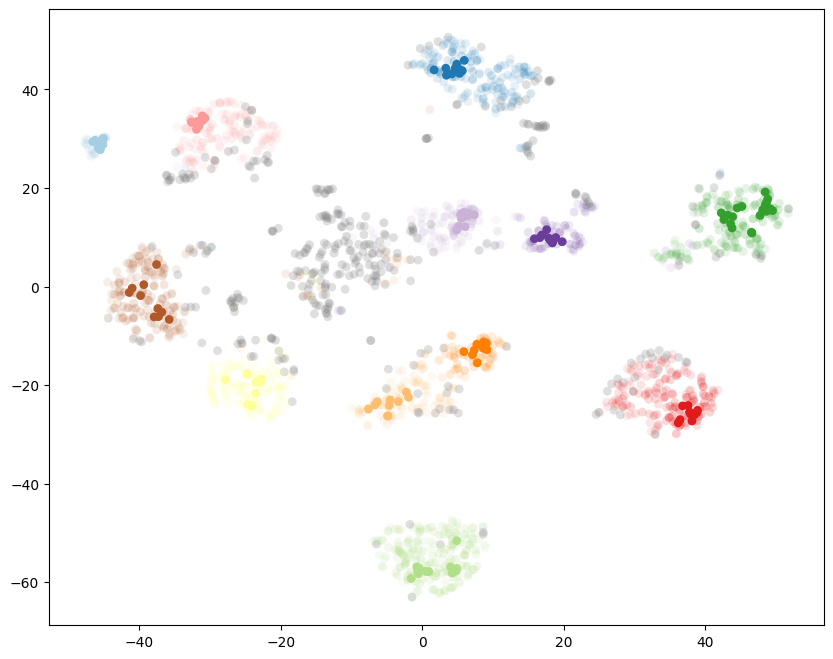

In [565]:
plt.figure(figsize=(10, 8))
plt.scatter(*projection.T, s=40, linewidth=0, c=new_colors, edgecolors='none')

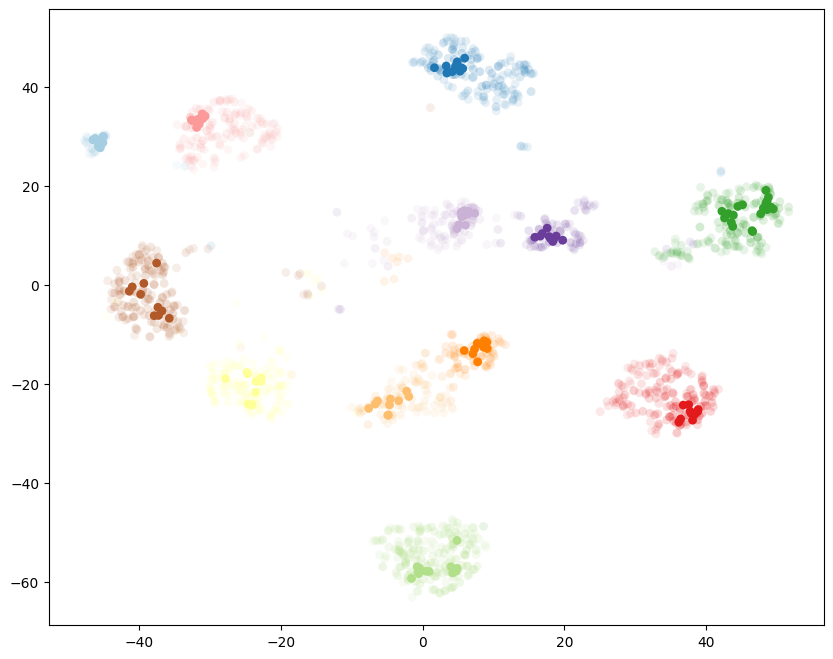

In [566]:
# Exclude noise points for better visualization
mask = np.array(new_labels) >= 0
proj_masked = projection[mask]
colors_masked = [c for c, m in zip(new_colors, mask) if m]
plt.figure(figsize=(10, 8))
plt.scatter(*proj_masked.T, s=40, linewidth=0, c=colors_masked, edgecolors='none')

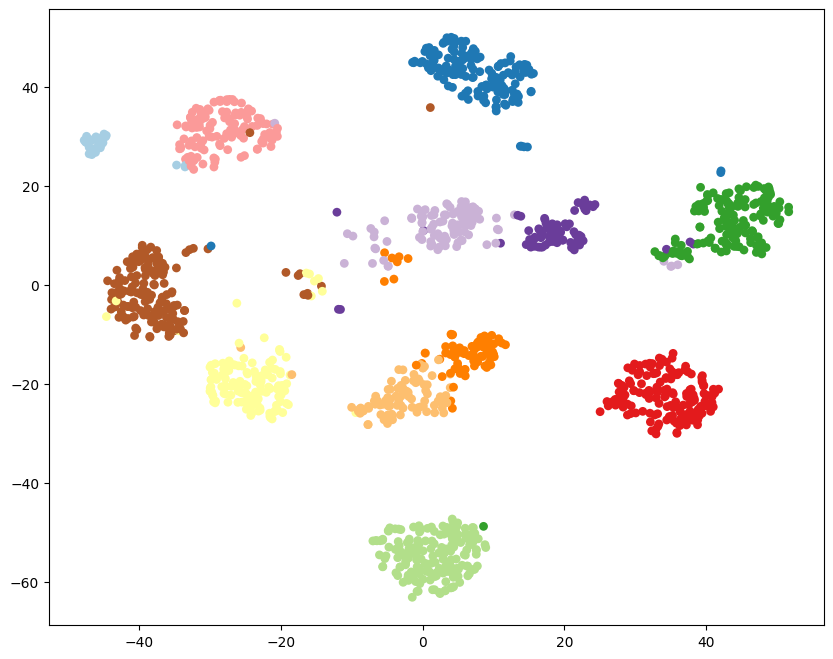

In [567]:
plt.figure(figsize=(10, 8))
plt.scatter(*proj_masked.T, s=40, linewidth=0, c=colors_masked, edgecolors='none', alpha=1)
plt.savefig("images/new_clustering")

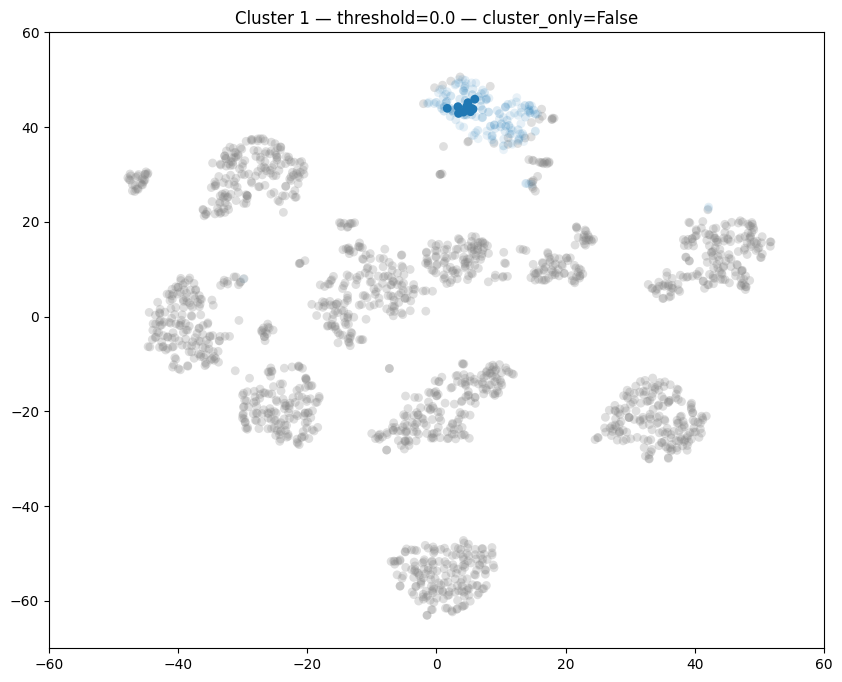

In [568]:
cluster_choice = 1   # label to visualize
membership_threshold = 0.0  # show only points with normalized probability > threshold
show_only_cluster = False  # if True, plot only chosen-cluster points

probs = new_probabilities_norm

base = hard_color_palette[cluster_choice] if (cluster_choice >= 0 and cluster_choice < len(hard_color_palette)) else (0.5, 0.5, 0.5)

labels_arr = np.array(new_labels, dtype=int)
mask_choice = labels_arr == int(cluster_choice)

n_points = projection.shape[0]
colors = np.zeros((n_points, 4))
colors[:, :3] = (0.5, 0.5, 0.5)  
colors[:, 3] = 0.25

if mask_choice.any():
    alphas = np.clip(probs, 0.0, 1.0)
    colors[mask_choice, :3] = base
    colors[mask_choice, 3] = np.clip(alphas[mask_choice], 0.05, 1.0)

if show_only_cluster:
    # When showing only the chosen cluster, handle noise (-1) specially
    if cluster_choice == -1:
        # show all points labeled as noise regardless of membership threshold
        plot_mask = mask_choice
    else:
        plot_mask = mask_choice & (probs > membership_threshold)
else:
    plot_mask = probs > membership_threshold

plt.figure(figsize=(10, 8))
plt.xlim(-60, 60)
plt.ylim(-70, 60)
if show_only_cluster:
    # Plot only chosen-cluster points (do not plot other points)
    if plot_mask.any():
        plt.scatter(projection[plot_mask, 0], projection[plot_mask, 1], c=colors[plot_mask], s=40, linewidths=0, edgecolors='none')
else:
    # Plot background (not-selected) and highlighted points
    plt.scatter(projection[~plot_mask, 0], projection[~plot_mask, 1], c=colors[~plot_mask], s=40, linewidths=0, edgecolors='none')
    plt.scatter(projection[plot_mask, 0], projection[plot_mask, 1], c=colors[plot_mask], s=40, linewidths=0, edgecolors='none')
plt.title(f'Cluster {cluster_choice} — threshold={membership_threshold} — cluster_only={show_only_cluster}')
plt.show()

In [569]:
# Imports for interactive plot
import plotly.graph_objects as go
from ipywidgets import Output, VBox
from IPython.display import clear_output

In [570]:
# Build interactive plot
n_points = projection.shape[0]
indices = np.arange(n_points)

colors = new_cluster_colors

# Build FigureWidget with index in customdata for lookup on click
fig = go.FigureWidget(
    data=go.Scattergl(
        x=projection[:,0],
        y=projection[:,1],
        mode='markers',
        marker=dict(size=8, color=[f'rgb({int(255*c[0])},{int(255*c[1])},{int(255*c[2])})' for c in colors]),
        customdata=indices,
        hovertemplate='index: %{customdata}<extra></extra>'
    ),
    layout=go.Layout(title='Interactive 2D projection of Digits dataset', width=1080, height=800)
)

out = Output()

def on_point_click(trace, points, selector):
    if len(points.point_inds) == 0:
        return
    i = points.point_inds[0]
    idx = int(trace.customdata[i])  # original index
    with out:
        clear_output(wait=True)
        fig_title = f'Point id: {idx}'

        plt.figure(figsize=(2,2))
        plt.imshow(digits.images[idx], cmap='gray')
        print("Original target:" + str(digits.target[idx]))
        print("Label from clustering:" + str(hard_clusterer.labels_[idx]))
        print("Label after re-clustering:" + str(new_labels[idx]))
        plt.title(fig_title)
        plt.axis('off')
        plt.show()


# Attach handler and display
scatter = fig.data[0]
scatter.on_click(on_point_click)

display(VBox([fig, out]))

    'data': [{'customdata': {'bdata': ('AAABAAIAAwAEAAUABgAHAAgACQAKAA' ... 'b6B…

## Analysis of a label subset

### Select a subset of k labels and consider only them


In [571]:
# Show occurrences in each cluster
soft_clust_dict

{2: 172,
 9: 18,
 -1: 839,
 5: 159,
 11: 70,
 3: 131,
 1: 136,
 4: 102,
 8: 68,
 6: 26,
 7: 19,
 10: 37,
 0: 20}

In [572]:
# Sort dictionary by label
sorted_soft_dict = dict(sorted(soft_clust_dict.items(), key=lambda item: item[0])) 

sorted_soft_dict

{-1: 839,
 0: 20,
 1: 136,
 2: 172,
 3: 131,
 4: 102,
 5: 159,
 6: 26,
 7: 19,
 8: 68,
 9: 18,
 10: 37,
 11: 70}

In [573]:
# Set the size of the subset considered
subset_labels = [1, 2, 11]

In [574]:
soft_membership

array([[0.05197322, 0.05729871, 0.25788705, ..., 0.05307688, 0.09052542,
        0.06473627],
       [0.0504084 , 0.04686046, 0.03663357, ..., 0.07497948, 0.04353457,
        0.04750335],
       [0.06348371, 0.06868785, 0.06470138, ..., 0.07300455, 0.06140918,
        0.06257285],
       ...,
       [0.06243469, 0.05723128, 0.06028778, ..., 0.06147589, 0.06085098,
        0.05998426],
       [0.05858826, 0.06040728, 0.08056707, ..., 0.07424964, 0.09849795,
        0.08092192],
       [0.06433618, 0.05451673, 0.06513587, ..., 0.05537234, 0.07567997,
        0.0726488 ]], shape=(1797, 12))

In [575]:
def build_subset_membership(subset_labels, membership):
    subset_membership = membership.copy()

    for i in range(subset_membership.shape[0]):
        for j in range(subset_membership.shape[1]):
            if j not in subset_labels:
                subset_membership[i][j] = 0 

    return subset_membership

In [576]:
subset_membership = build_subset_membership(subset_labels, soft_membership)

subset_membership

array([[0.        , 0.05729871, 0.25788705, ..., 0.        , 0.        ,
        0.06473627],
       [0.        , 0.04686046, 0.03663357, ..., 0.        , 0.        ,
        0.04750335],
       [0.        , 0.06868785, 0.06470138, ..., 0.        , 0.        ,
        0.06257285],
       ...,
       [0.        , 0.05723128, 0.06028778, ..., 0.        , 0.        ,
        0.05998426],
       [0.        , 0.06040728, 0.08056707, ..., 0.        , 0.        ,
        0.08092192],
       [0.        , 0.05451673, 0.06513587, ..., 0.        , 0.        ,
        0.0726488 ]], shape=(1797, 12))

In [577]:
# Import libraries for pie-charts
from matplotlib.patches import Wedge, Patch

In [578]:
lim = [-60, 60, -70, 60]

In [579]:
# Draw a small pie at each projection point showing subset_membership for subset_labels

def plot_projection_with_pies(projection, subset_membership, subset_labels, color_palette, lim, figsize=(12, 10), size_frac=0.02):
    """Plot a small pie at each 2D point in `projection`.

    - `subset_membership` should be an (n_points, n_clusters) membership matrix.
    - `subset_labels` is an iterable of cluster labels to show as slices in the pie.
    - `color_palette` is a sequence of RGB tuples (0..1) or matplotlib color specs.
    """
    fig, ax = plt.subplots(figsize=figsize)
    # radius (in data units) proportional to data span
    x_span = np.ptp(projection[:, 0]) if projection.shape[0] > 0 else 1.0
    y_span = np.ptp(projection[:, 1]) if projection.shape[0] > 0 else 1.0
    r = size_frac * max(x_span, y_span)

    cols = np.array(subset_labels, dtype=int)
    # prepare colors for subset labels (fall back to gray)
    n_pal = len(color_palette)
    colors = {lab: color_palette[int(lab) % n_pal] if int(lab) >= 0 else (0.5, 0.5, 0.5) for lab in cols}

    for i, (x, y) in enumerate(projection):
        vals = np.array(subset_membership[i])
        sel = vals[cols]
        total = float(sel.sum())
        if total <= 0:
            # draw a small gray dot if no membership in subset
            ax.scatter(x, y, color='lightgray', s=(r * 1000), linewidths=0, zorder=1)
            continue
        start = 0.0
        for lab, v in zip(cols, sel):
            if v <= 0:
                continue
            theta1 = 360.0 * start
            theta2 = 360.0 * (start + v / total)
            wedge = Wedge((x, y), r, theta1, theta2, facecolor=colors[int(lab)], edgecolor='none', linewidth=0, zorder=2)
            ax.add_patch(wedge)
            start += v / total

    # Legend for subset labels
    legend_handles = [Patch(facecolor=colors[int(l)], label=f'Cluster {l}') for l in cols]
    ax.legend(handles=legend_handles, bbox_to_anchor=(1.02, 1), loc='upper left')
    ax.set_aspect('equal', adjustable='datalim')
    ax.set_xlabel('TSNE-1')
    ax.set_ylabel('TSNE-2')
    ax.set_title('Projection — pie per point (subset membership)')
    plt.xlim(lim[0], lim[1])
    plt.ylim(lim[2], lim[3])
    plt.tight_layout()
    return fig, ax


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


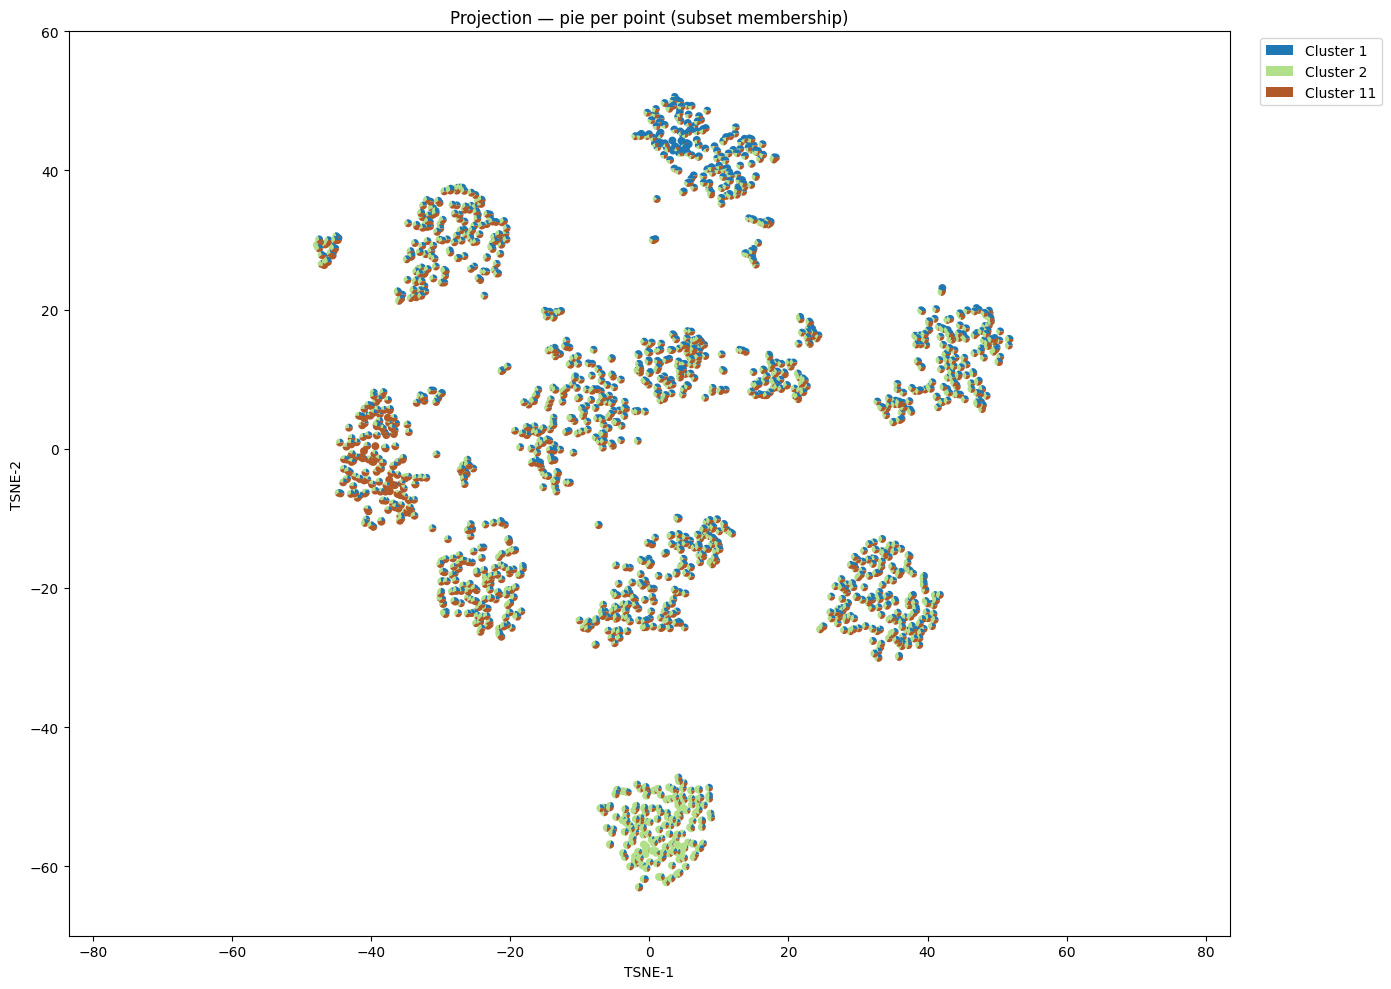

In [580]:
# Plot the piecharts
fig, ax = plot_projection_with_pies(projection, subset_membership, subset_labels, hard_color_palette, lim, figsize=(14,10), size_frac=0.005)
plt.show()

In [581]:
def build_residual_membership(subset_labels, membership):
    residual_membership = membership.copy()
    residual_arr = []

    for i in range(residual_membership.shape[0]):
        temp = 0
        for j in range(residual_membership.shape[1]):
            if j not in subset_labels:
                temp += residual_membership[i][j]
                residual_membership[i][j] = 0

        residual_arr.append(np.append(residual_membership[i], temp))
        

    return np.array(residual_arr)

In [582]:
residual_membership = build_residual_membership(subset_labels, soft_membership)

residual_membership

array([[0.        , 0.05729871, 0.25788705, ..., 0.        , 0.06473627,
        0.5781544 ],
       [0.        , 0.04686046, 0.03663357, ..., 0.        , 0.04750335,
        0.5102179 ],
       [0.        , 0.06868785, 0.06470138, ..., 0.        , 0.06257285,
        0.57768007],
       ...,
       [0.        , 0.05723128, 0.06028778, ..., 0.        , 0.05998426,
        0.57074166],
       [0.        , 0.06040728, 0.08056707, ..., 0.        , 0.08092192,
        0.60956204],
       [0.        , 0.05451673, 0.06513587, ..., 0.        , 0.0726488 ,
        0.57106864]], shape=(1797, 13))

In [583]:
residual_labels = [1,2,11,12]

print(residual_labels)

[1, 2, 11, 12]


In [584]:
# Plot the piecharts
fig, ax = plot_projection_with_pies(projection, residual_membership, residual_labels, hard_color_palette, figsize=(14,10), size_frac=0.005)
plt.show()

TypeError: plot_projection_with_pies() missing 1 required positional argument: 'lim'

### Keep the highest k probabilities for each point

In [ ]:
def keep_highest_k_prob(k, membership):
    highest_membership = membership.copy()
    for i in range(highest_membership.shape[0]):
        temp = np.argpartition(-highest_membership[i], k)
        topK = temp[:k]

        for j in range(highest_membership.shape[1]):
            if j not in topK:
                highest_membership[i][j] = 0
    
    return highest_membership


In [ ]:
defined_k = 3
highest_membership = keep_highest_k_prob(defined_k, soft_membership)

highest_membership

array([[0.        , 0.        , 0.25788705, ..., 0.        , 0.09052542,
        0.        ],
       [0.0504084 , 0.        , 0.        , ..., 0.07497948, 0.        ,
        0.        ],
       [0.        , 0.06868785, 0.        , ..., 0.07300455, 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.08056707, ..., 0.        , 0.09849795,
        0.08092192],
       [0.        , 0.        , 0.        , ..., 0.        , 0.07567997,
        0.0726488 ]], shape=(1797, 12))

In [ ]:
full_labels = list(range(soft_membership.shape[1]))

full_labels

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


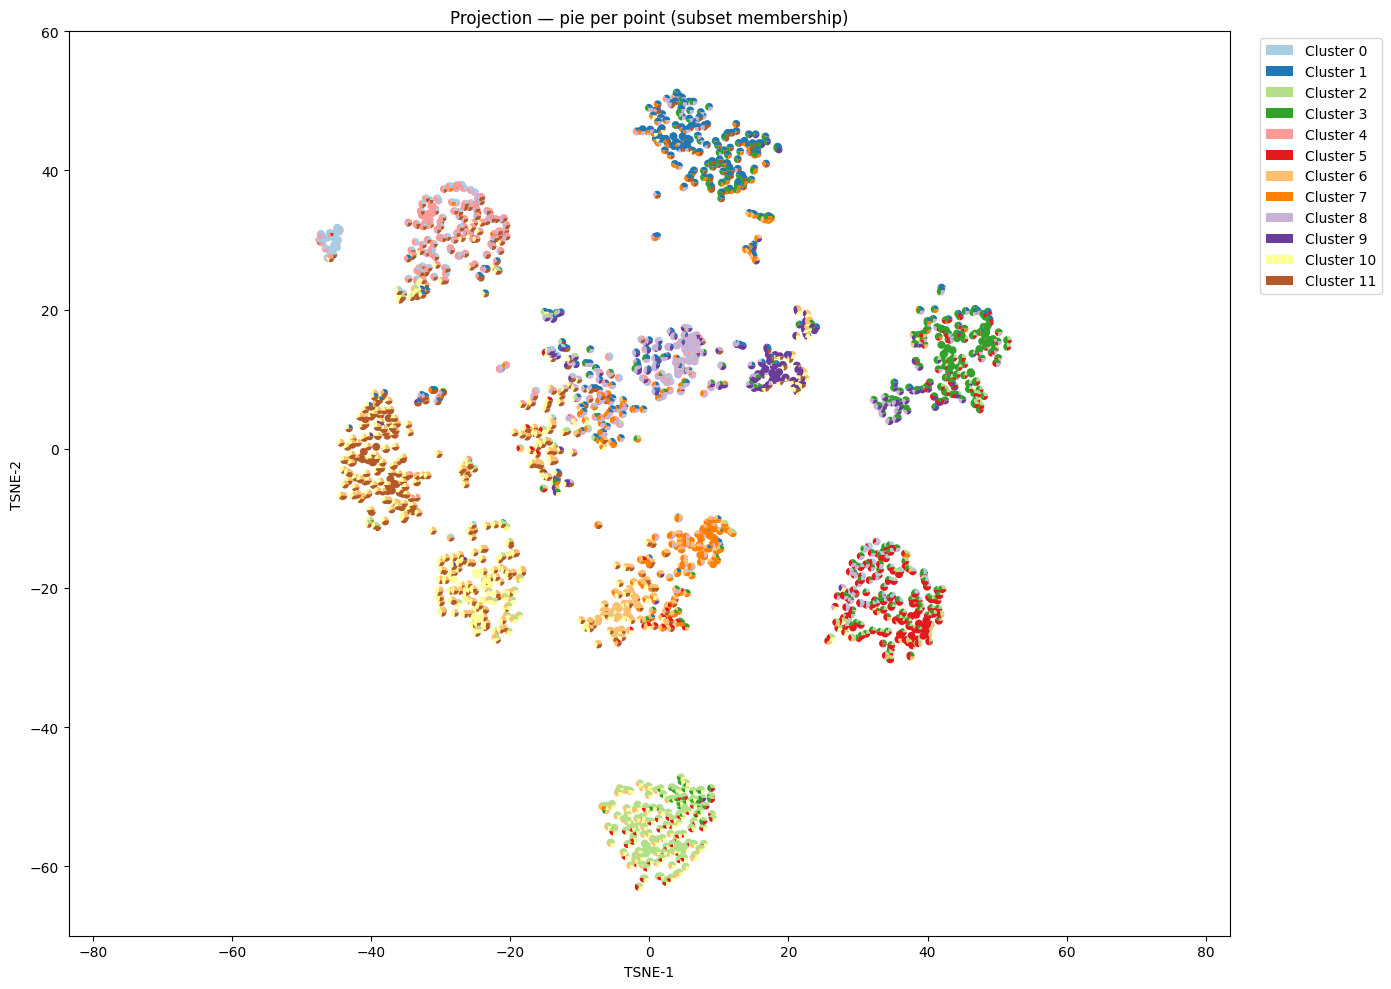

In [ ]:
# Plot the piecharts
fig, ax = plot_projection_with_pies(projection, highest_membership, full_labels, hard_color_palette, figsize=(14,10), size_frac=0.005)
plt.show()

In [ ]:
def keep_k_with_residual(k, membership):
    highest_membership = membership.copy()
    residual_arr = []

    for i in range(highest_membership.shape[0]):
        temp = np.argpartition(-highest_membership[i], k)
        topK = temp[:k]
        temp_sum = 0

        for j in range(highest_membership.shape[1]):
            if j not in topK:
                temp_sum += highest_membership[i][j]
                highest_membership[i][j] = 0

        residual_arr.append(np.append(highest_membership[i], temp_sum))
    
    return np.array(residual_arr)

In [ ]:
k_residual_membership = keep_k_with_residual(defined_k, soft_membership)

In [ ]:
full_res_labels = list(range(soft_membership.shape[1]))
full_res_labels.append(12)

print(full_res_labels)

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


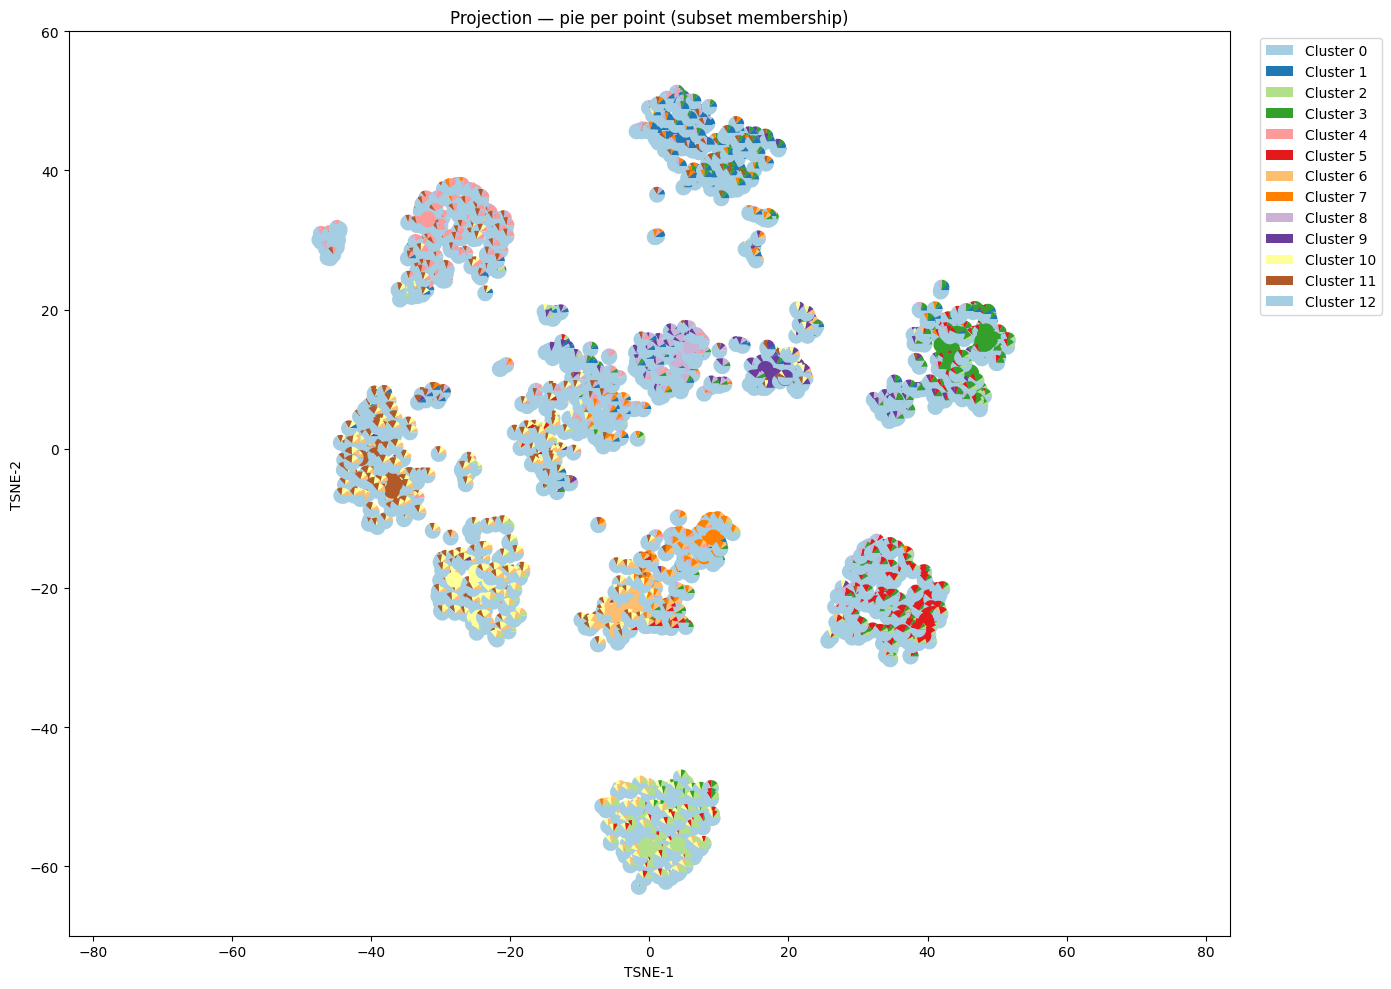

In [ ]:
# Plot the piecharts
fig, ax = plot_projection_with_pies(projection, k_residual_membership, full_res_labels, hard_color_palette, figsize=(14,10), size_frac=0.01)
plt.show()

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


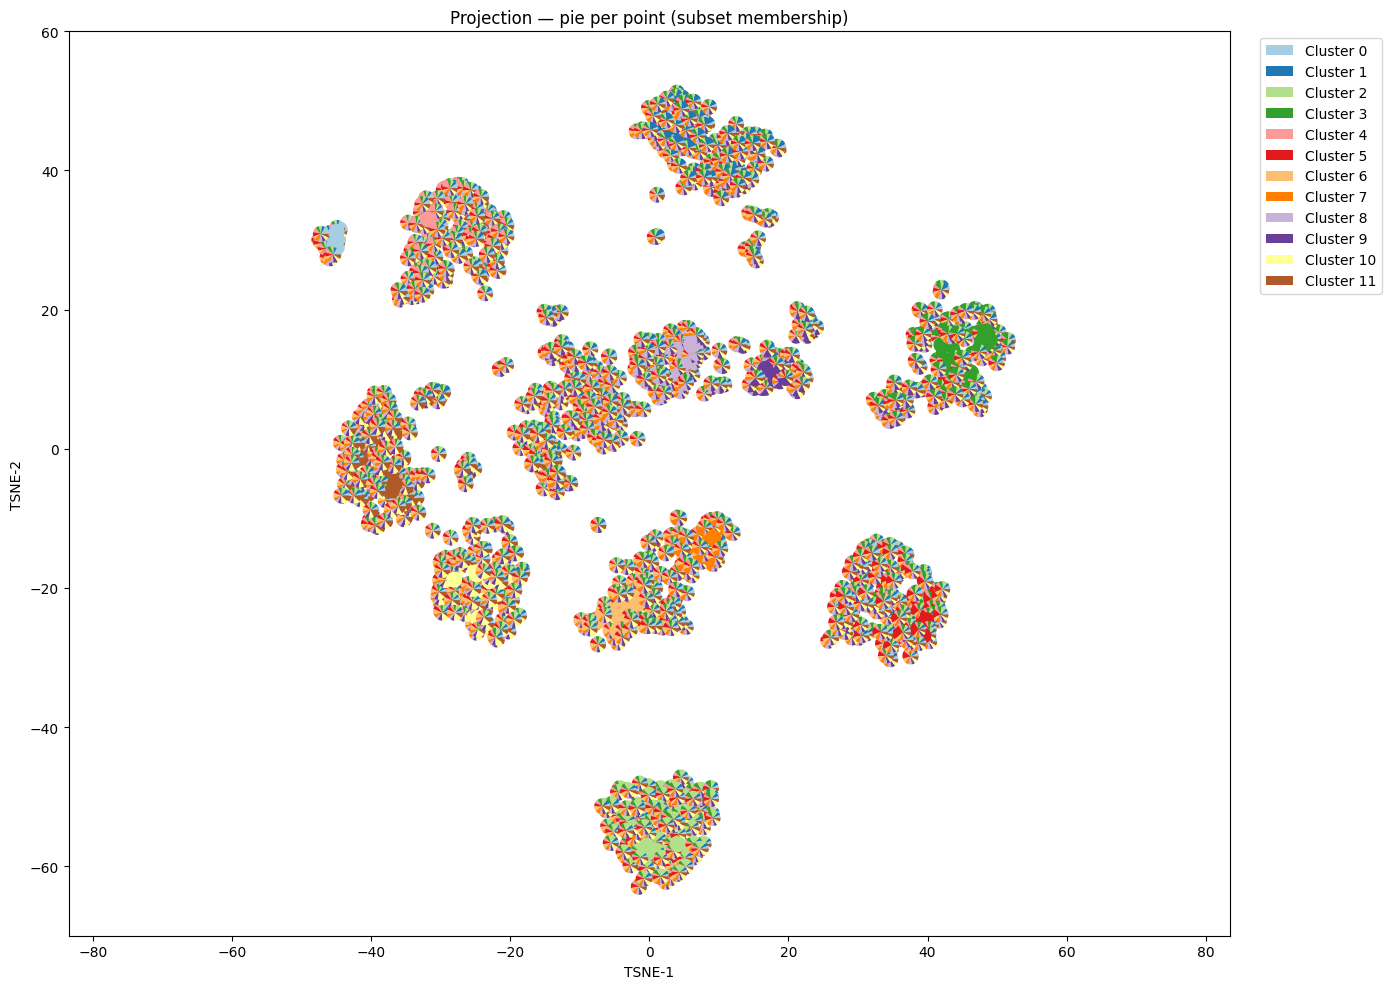

In [ ]:
# Plot the piecharts
fig, ax = plot_projection_with_pies(projection, soft_membership, full_labels, hard_color_palette, figsize=(14,10), size_frac=0.01)
plt.show()

In [ ]:
# Interactive projection + large pie on click
# Shows a big pie for the clicked point's membership vector (uses subset_membership if present)
from ipywidgets import HBox, VBox, Output, Layout
import matplotlib.colors as mcolors
from IPython.display import display, HTML

# Choose membership matrix and labels
membership = residual_membership

labels = residual_labels

palette = hard_color_palette

label_colors = [mcolors.to_hex(palette[int(l) % len(palette)]) for l in labels]

# Build scatter FigureWidget
n_points = projection.shape[0]
indices = list(range(n_points))
scatter = go.FigureWidget(
    data=go.Scattergl(
        x=projection[:, 0],
        y=projection[:, 1],
        mode='markers',
        marker=dict(size=6, color='lightgray'),
        customdata=indices,
        hovertemplate='index: %{customdata}<extra></extra>'
    ),
    layout=go.Layout(title='Click a point to show membership pie', width=900, height=700)
)

# Pre-build pie FigureWidget (empty)
pie_fig = go.FigureWidget(layout=go.Layout(title='Membership (click a point)', width=450, height=450))
pie_fig.add_trace(go.Pie(labels=[f'Cluster {l}' for l in labels], values=[0]*len(labels), marker=dict(colors=label_colors)))

info_out = Output()

# Click handler updates the pie chart and information panel
def on_point_click(trace, points, selector):
    if len(points.point_inds) == 0:
        return
    i = points.point_inds[0]
    idx = int(trace.customdata[i])
    vals = membership[idx]
    sel_vals = [float(vals[int(l)]) for l in labels]
    total = sum(sel_vals)

    with info_out:
        info_out.clear_output()
        if total <= 0:
            display(HTML(f"<b>Point {idx}</b><br>No membership in selected labels"))
        else:
            pie_fig.data[0].values = sel_vals
            pie_fig.layout.title = f'Point {idx} — membership pie (sum={total:.3f})'
            # display(HTML(f"<b>Point {idx}</b><br>Label (hard): {int(hard_clusterer.labels_[idx]) if 'hard_clusterer' in globals() else 'n/a'}<br>Label (new): {int(new_labels[idx]) if 'new_labels' in globals() else 'n/a'}"))

            # plt.figure(figsize=(2,2))
            # plt.imshow(digits.images[idx], cmap='gray')
            print("Original target:" + str(digits.target[idx]))
            print("Label from clustering:" + str(hard_clusterer.labels_[idx]))
            print("Label after re-clustering:" + str(new_labels[idx]))

# Attach handler
scatter.data[0].on_click(on_point_click)

# Display side-by-side: scatter | (pie + info)
right_col = VBox([pie_fig, info_out], layout=Layout(width='480px'))
display(HBox([scatter, right_col]))


    'data': [{'customdata': [0, 1, 2, ..., 1794, 1795, 1796],
              'hov…

## Experiments with reduced digits set

In [ ]:
digits = datasets.load_digits()

digits

{'data': array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
        [ 0.,  0.,  0., ..., 10.,  0.,  0.],
        [ 0.,  0.,  0., ..., 16.,  9.,  0.],
        ...,
        [ 0.,  0.,  1., ...,  6.,  0.,  0.],
        [ 0.,  0.,  2., ..., 12.,  0.,  0.],
        [ 0.,  0., 10., ..., 12.,  1.,  0.]], shape=(1797, 64)),
 'target': array([0, 1, 2, ..., 8, 9, 8], shape=(1797,)),
 'frame': None,
 'feature_names': ['pixel_0_0',
  'pixel_0_1',
  'pixel_0_2',
  'pixel_0_3',
  'pixel_0_4',
  'pixel_0_5',
  'pixel_0_6',
  'pixel_0_7',
  'pixel_1_0',
  'pixel_1_1',
  'pixel_1_2',
  'pixel_1_3',
  'pixel_1_4',
  'pixel_1_5',
  'pixel_1_6',
  'pixel_1_7',
  'pixel_2_0',
  'pixel_2_1',
  'pixel_2_2',
  'pixel_2_3',
  'pixel_2_4',
  'pixel_2_5',
  'pixel_2_6',
  'pixel_2_7',
  'pixel_3_0',
  'pixel_3_1',
  'pixel_3_2',
  'pixel_3_3',
  'pixel_3_4',
  'pixel_3_5',
  'pixel_3_6',
  'pixel_3_7',
  'pixel_4_0',
  'pixel_4_1',
  'pixel_4_2',
  'pixel_4_3',
  'pixel_4_4',
  'pixel_4_5',
  'pixel_4_6',
  'pixel_4_7'

In [ ]:
chosen_targets = [2, 3, 7, 8]

In [ ]:
reduced_digits = []
reduced_targets = []

for i in range(len(digits.data)):
    if digits.target[i] in chosen_targets:
        reduced_digits.append(digits.data[i])
        reduced_targets.append(int(digits.target[i]))

In [ ]:
print(len(reduced_digits))
print(len(reduced_targets))

713
713


In [ ]:
reduced_digits = np.array(reduced_digits)

reduced_digits

array([[ 0.,  0.,  0., ..., 16.,  9.,  0.],
       [ 0.,  0.,  7., ...,  9.,  0.,  0.],
       [ 0.,  0.,  7., ...,  0.,  0.,  0.],
       ...,
       [ 0.,  0.,  5., ...,  3.,  0.,  0.],
       [ 0.,  0.,  1., ...,  6.,  0.,  0.],
       [ 0.,  0., 10., ..., 12.,  1.,  0.]], shape=(713, 64))

In [ ]:
# Project data into two dimensions to visualize via t-SNE
reduced_projection = TSNE().fit_transform(reduced_digits)

reduced_projection

array([[-12.415818  ,  18.079039  ],
       [ -9.437917  , -20.289236  ],
       [ 38.12948   ,  10.073697  ],
       ...,
       [  0.24566461,  14.637575  ],
       [ -0.7439438 ,  13.475024  ],
       [ -2.4329891 ,   8.856167  ]], shape=(713, 2), dtype=float32)

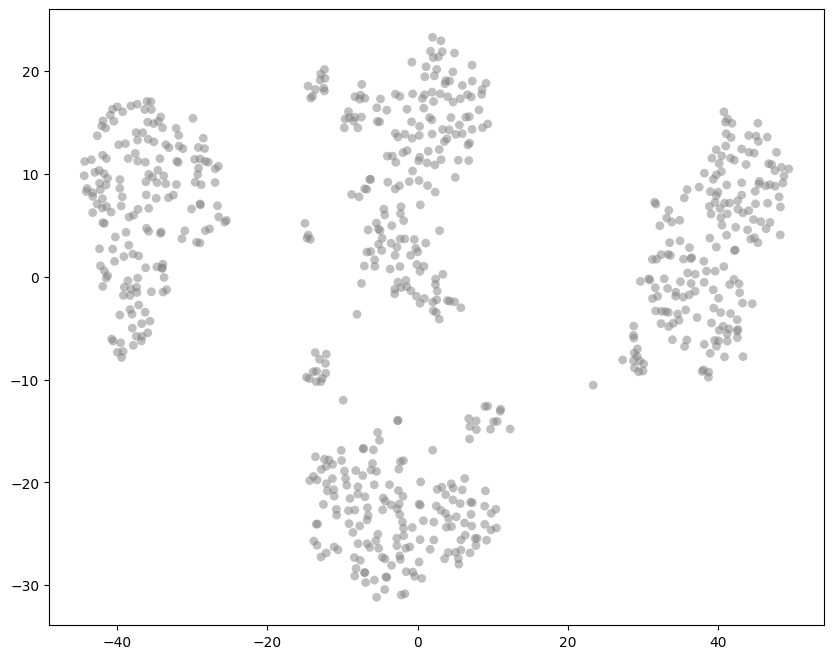

In [ ]:
# Plot data in 2-dimensional space
# Plotting arguments: s = marker size, c = color (RGBA array), alpha = transparency
plt.figure(figsize=(10, 8))
plt.scatter(*reduced_projection.T, s=40, linewidth=0, color=[0.5, 0.5, 0.5], alpha=0.5, edgecolors='none')

### Hard Clustering

In [ ]:
# Hard Clustering
r_hard_clusterer = hdbscan.HDBSCAN(min_cluster_size=10, prediction_data=False).fit(reduced_digits)

d:\Projects\Thesis\ClusteringTrial\.venv\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

d:\Projects\Thesis\ClusteringTrial\.venv\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



In [ ]:
# Count number of data points in each cluster
r_hard_clust_dict = dict()

for i in r_hard_clusterer.labels_:
    if int(i) in r_hard_clust_dict:
        r_hard_clust_dict[int(i)] += 1
    else:
        r_hard_clust_dict[int(i)] = 1

In [ ]:
# Show how many clusters are found: -1 represents noise cluster
len(r_hard_clust_dict.keys())

5

In [ ]:
# Show occurrences in each cluster
r_hard_clust_dict

{-1: 300, 1: 120, 0: 145, 2: 102, 3: 46}

In [ ]:
# Sort dictionary by label
r_sorted_hard_dict = dict(sorted(r_hard_clust_dict.items(), key=lambda item: item[0])) 

r_sorted_hard_dict

{-1: 300, 0: 145, 1: 120, 2: 102, 3: 46}

In [ ]:
# Set colors for hard clusters
r_hard_color_palette = sns.color_palette('tab10', len(r_hard_clust_dict.keys())-1)
r_hard_cluster_colors = [r_hard_color_palette[x] if x >= 0
                  else (0.5, 0.5, 0.5)
                  for x in r_hard_clusterer.labels_]
r_hard_member_colors = [sns.desaturate(x, p) for x, p in
                         zip(r_hard_cluster_colors, r_hard_clusterer.probabilities_)]

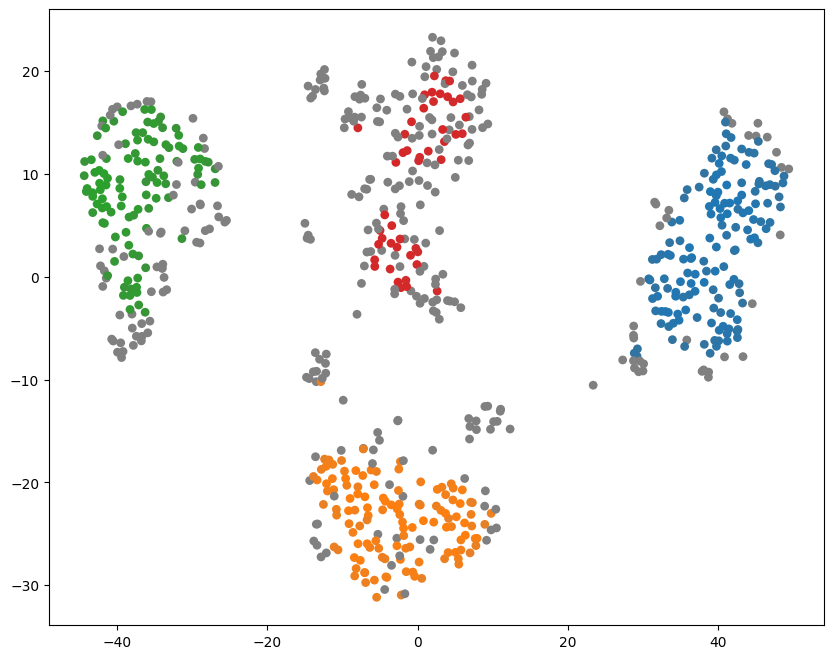

In [ ]:
# Plot hard clustering results
plt.figure(figsize=(10, 8))
plt.scatter(*reduced_projection.T, s=40, linewidth=0, c=r_hard_member_colors, edgecolors='none')
plt.savefig("images/hard_clustering_2378")

In [ ]:
reduced_projection_orig = []

for i in range(len(data)):
    if digits.target[i] in chosen_targets:
        reduced_projection_orig.append(projection[i])

reduced_projection_orig = np.array(reduced_projection_orig)

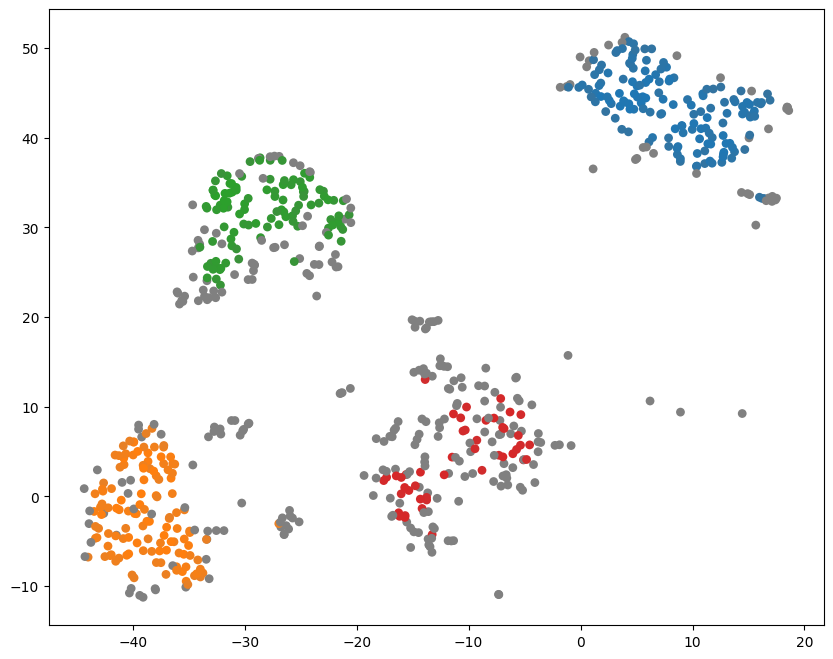

In [ ]:
# Plot hard clustering results
plt.figure(figsize=(10, 8))
plt.scatter(*reduced_projection_orig.T, s=40, linewidth=0, c=r_hard_member_colors, edgecolors='none')
plt.savefig("images/hard_clustering_2378_orig")

### Soft Clustering

In [ ]:
# Soft Clustering
r_soft_clusterer = hdbscan.HDBSCAN(min_cluster_size=10, prediction_data=True).fit(reduced_digits)

d:\Projects\Thesis\ClusteringTrial\.venv\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

d:\Projects\Thesis\ClusteringTrial\.venv\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



In [ ]:
# Show soft membership vectors
r_soft_membership = all_points_membership_vectors(r_soft_clusterer)

r_soft_membership

array([[0.16085316, 0.14653307, 0.15690151, 0.20437913],
       [0.11810099, 0.44249786, 0.16047051, 0.16599617],
       [0.29582922, 0.14577476, 0.12874363, 0.15605419],
       ...,
       [0.14208885, 0.1497696 , 0.15601151, 0.23834143],
       [0.13540341, 0.14071485, 0.15869936, 0.30849791],
       [0.12229902, 0.16297524, 0.1534016 , 0.22918876]], shape=(713, 4))

In [ ]:
# Define parameters for visualization
r_n_points = r_soft_membership.shape[0]
r_n_clusters = r_soft_membership.shape[1]
r_cols = 2
r_rows = int(np.ceil(r_n_clusters / r_cols))

r_n_points, r_n_clusters

(713, 4)

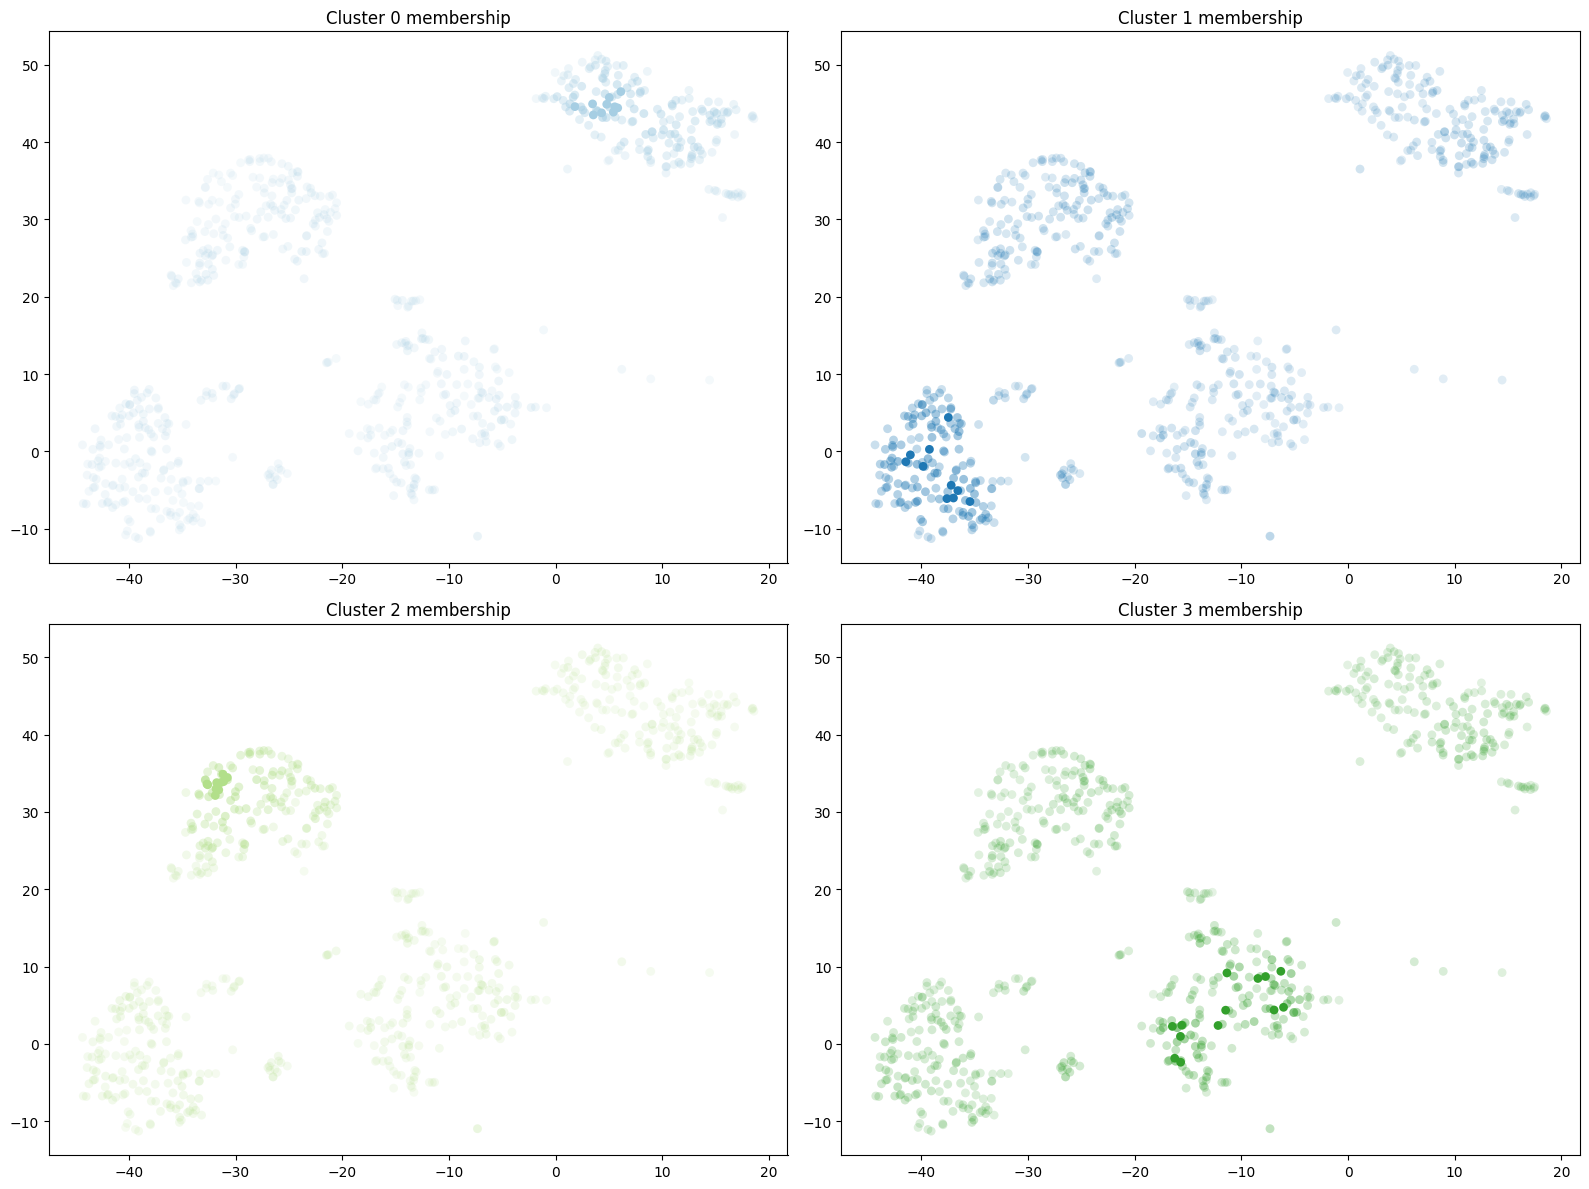

In [ ]:
print_soft_membership(r_rows, r_cols, r_n_clusters, reduced_projection_orig, sharpen_factor, r_soft_membership)

In [ ]:
r_soft_avg = np.average(r_soft_membership)
print(r_soft_avg)

0.20243596810117467


In [ ]:
r_soft_threshold = []
r_add_param = 0.01


for i in range(r_n_clusters):
    r_soft_threshold.append(float(np.average(r_soft_membership[:,i]))+r_add_param)

r_soft_threshold

[0.2049213528781584,
 0.2243291783073253,
 0.19346642889469554,
 0.22702691232451946]

In [ ]:
r_new_labels = []
r_new_probabilities = []


for i in range(r_n_points):
    r_id_max_membership = np.argmax(r_soft_membership[i])
    if np.max(r_soft_membership[i]) > r_soft_threshold[r_id_max_membership]:
        r_new_labels.append(int(r_id_max_membership))
        r_new_probabilities.append(r_soft_membership[i][r_id_max_membership])
    else:
        r_new_labels.append(-1)
        r_new_probabilities.append(0)

In [ ]:
# Count number of data points in each cluster
r_new_clust_dict = dict()

for i in r_new_labels:
    if int(i) in r_new_clust_dict:
        r_new_clust_dict[int(i)] += 1
    else:
        r_new_clust_dict[int(i)] = 1

In [ ]:
r_count_diff = 0

for i in range(r_n_points):
    if r_new_labels[i] != r_hard_clusterer.labels_[i]:
        r_count_diff += 1
    
print(str(r_count_diff) + " points have been re-clustered")

166 points have been re-clustered


In [ ]:
r_new_probabilities_norm = min_max_scale(np.array(r_new_probabilities))
print(r_new_probabilities_norm)

[0.         0.44249786 0.29582922 0.28188738 0.29656928 0.43147651
 0.28583813 0.27360036 0.31667715 0.3251187  0.21159591 0.27181005
 0.         1.         0.28050024 0.41261652 0.32694314 0.
 0.         0.31342529 0.         0.         0.         0.3572579
 0.40237027 0.27587005 0.41349711 0.40988759 0.         0.42065109
 0.         1.         0.35994323 0.34528782 0.22415352 0.36680567
 0.34980006 0.43875721 0.25450433 0.331049   0.         0.30261504
 0.45708611 0.         0.40634048 0.         0.         0.35339647
 0.29067017 0.25375223 0.         0.         0.35406576 0.27130186
 0.39500328 0.29868015 0.         0.36715305 0.30846171 1.
 0.         0.3425272  0.34104872 0.25442327 0.3782355  0.2320044
 0.35023678 0.37775941 1.         0.32406594 0.29696374 0.43991809
 1.         0.3157032  0.36087961 0.33784097 0.28906141 0.
 0.26008511 0.40352682 0.         0.         0.279384   0.21376675
 0.40710854 0.32255569 0.26073493 0.30568252 0.45331769 0.40029134
 0.28085013 0.2582241

In [ ]:
# Set colors for clusters

r_color_palette = sns.color_palette('tab10', r_n_clusters)

r_new_cluster_colors = [r_color_palette[x] if x >= 0
                  else (0.5, 0.5, 0.5)
                  for x in r_new_labels]
r_new_member_colors = [sns.desaturate(x, p) for x, p in zip(r_new_cluster_colors, r_new_probabilities_norm)]

In [ ]:
r_new_colors = []

for i in range(len(r_new_cluster_colors)):
    r_new_colors.append(list(r_new_cluster_colors[i]))
    if(r_new_probabilities_norm[i] > 0):
        r_new_colors[i].append(r_new_probabilities_norm[i])
    else:
        r_new_colors[i].append(0.25)

r_new_colors

[[0.5, 0.5, 0.5, 0.25],
 [1.0,
  0.4980392156862745,
  0.054901960784313725,
  np.float64(0.44249786123202545)],
 [0.12156862745098039,
  0.4666666666666667,
  0.7058823529411765,
  np.float64(0.29582921952859303)],
 [0.8392156862745098,
  0.15294117647058825,
  0.1568627450980392,
  np.float64(0.2818873831172179)],
 [0.17254901960784313,
  0.6274509803921569,
  0.17254901960784313,
  np.float64(0.2965692752090993)],
 [1.0,
  0.4980392156862745,
  0.054901960784313725,
  np.float64(0.43147650558379835)],
 [0.12156862745098039,
  0.4666666666666667,
  0.7058823529411765,
  np.float64(0.2858381322950048)],
 [0.8392156862745098,
  0.15294117647058825,
  0.1568627450980392,
  np.float64(0.27360036193549553)],
 [0.17254901960784313,
  0.6274509803921569,
  0.17254901960784313,
  np.float64(0.3166771512360929)],
 [1.0,
  0.4980392156862745,
  0.054901960784313725,
  np.float64(0.3251186976709357)],
 [0.12156862745098039,
  0.4666666666666667,
  0.7058823529411765,
  np.float64(0.211595907942

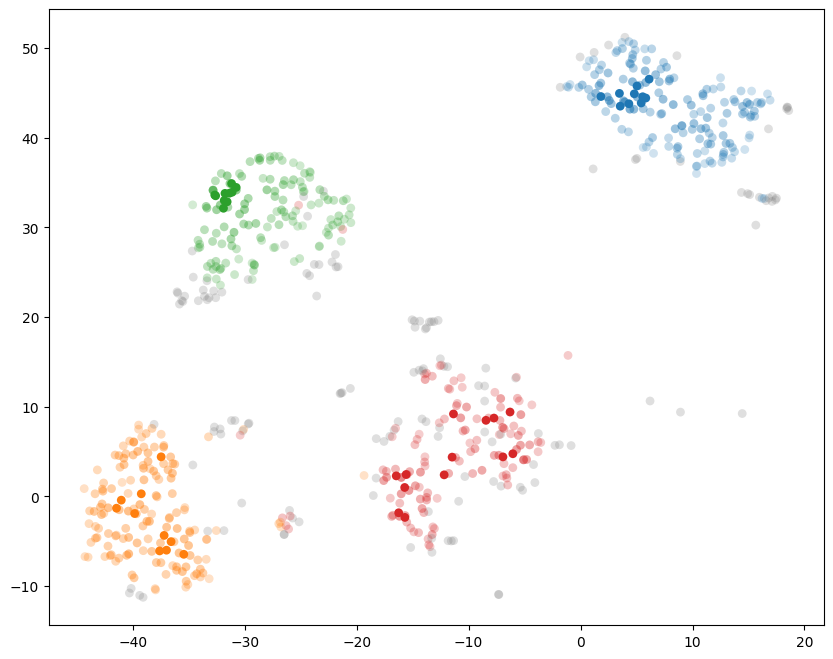

In [ ]:
plt.figure(figsize=(10, 8))
plt.scatter(*reduced_projection_orig.T, s=40, linewidth=0, c=r_new_colors, edgecolors='none')
plt.savefig("images/new_clustering_2378_orig")

In [ ]:
r_lim = [-30, 5, -15, 55]

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


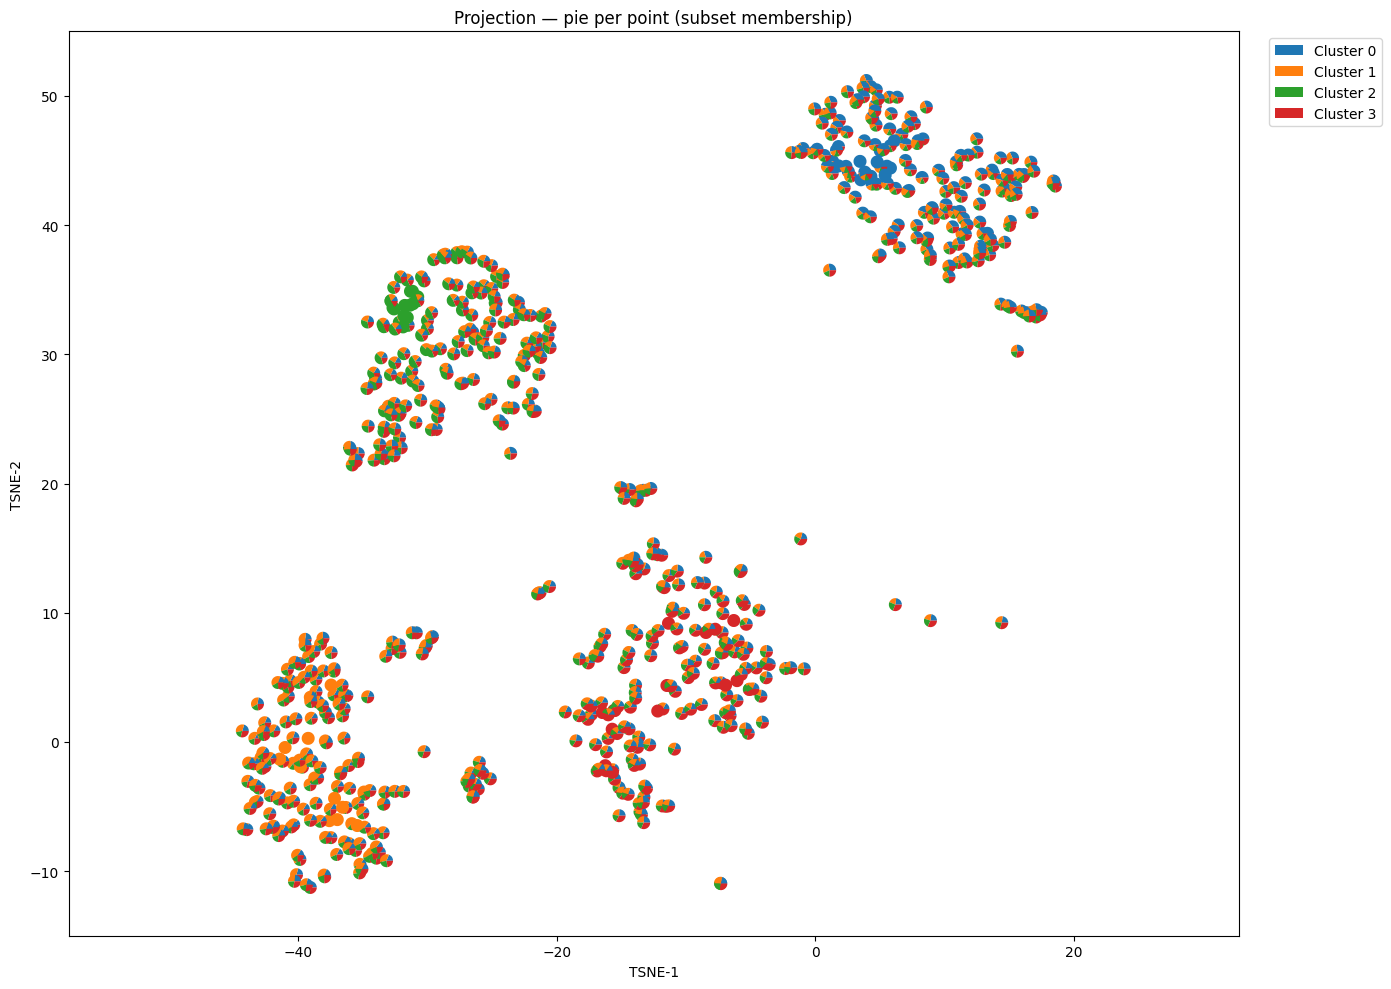

In [ ]:
# Plot the piecharts
fig, ax = plot_projection_with_pies(reduced_projection_orig, r_soft_membership, [0,1,2,3], r_hard_color_palette, r_lim, figsize=(14,10), size_frac=0.008)
plt.savefig("images/piechart_2378")
plt.show()

In [ ]:
import pickle

In [632]:
with open("saved/dbpedia_ctm/dbpedia_final_topics.pkl", "rb") as f:
    final_topics_for_all = pickle.load(f)

final_topics_for_all

[[(np.int64(376), np.float32(0.11505146)),
  (np.int64(446), np.float32(0.088142276))],
 [(np.int64(441), np.float32(0.078045))],
 [(np.int64(340), np.float32(0.05726418)),
  (np.int64(499), np.float32(0.041172963)),
  (np.int64(333), np.float32(0.03644754))],
 [(np.int64(468), np.float32(0.35153264))],
 [(np.int64(167), np.float32(0.074640356))],
 [(np.int64(374), np.float32(0.03213655)),
  (np.int64(71), np.float32(0.026141906)),
  (np.int64(479), np.float32(0.019770771))],
 [(np.int64(12), np.float32(0.061743535)),
  (np.int64(131), np.float32(0.054418124))],
 [(np.int64(226), np.float32(0.010404399)),
  (np.int64(466), np.float32(0.007909006))],
 [(np.int64(128), np.float32(0.0058702016)),
  (np.int64(321), np.float32(0.005547849))],
 [(np.int64(411), np.float32(0.033403285)),
  (np.int64(217), np.float32(0.0265131))],
 [(np.int64(231), np.float32(0.30115625)),
  (np.int64(131), np.float32(0.097781666))],
 [(np.int64(238), np.float32(0.15208493)),
  (np.int64(190), np.float32(0.064

In [653]:
def display_documents_grid(
    doc_ids,
    final_topics_for_all,
    top_k=None,
    ncols=3
):

    nrows = int(np.ceil(len(doc_ids) / ncols))

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(5 * ncols, 4.5 * nrows)
    )

    axes = np.atleast_1d(axes).flatten()

    for ax, doc_id in zip(axes, doc_ids):

        topics = sorted(
            final_topics_for_all[doc_id],
            key=lambda x: x[1],
            reverse=True
        )

        if top_k is not None:
            topics = topics[:top_k]

        if not topics:
            ax.set_title(f"Document {doc_id}: no topics", fontsize=14)
            ax.axis("off")
            continue

        topic_ids = [int(t[0]) for t in topics]

        weights = np.array(
            [float(t[1]) for t in topics]
        )

        relative_weights = weights / weights.sum()

        colors = plt.cm.tab10(
            np.arange(len(topics)) % 10
        )

        ax.pie(
            relative_weights,
            labels=[
                f"Topic {topic_id}"
                for topic_id in topic_ids
            ],
            colors=colors,
            autopct="%1.0f%%",
            startangle=90,
            counterclock=False,
            textprops={"fontsize": 12},
            wedgeprops={
                "edgecolor": "white",
                "linewidth": 0.8
            },
            radius=0.7,
            labeldistance=1.25,
        )

        ax.set_title(f"Document {doc_id}", fontsize=14)

    # Nasconde gli assi inutilizzati
    for ax in axes[len(doc_ids):]:
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(
            "documents_pie_after_assignment.pdf",
            format="pdf",
            bbox_inches="tight",
            pad_inches=0
        )
    plt.show()

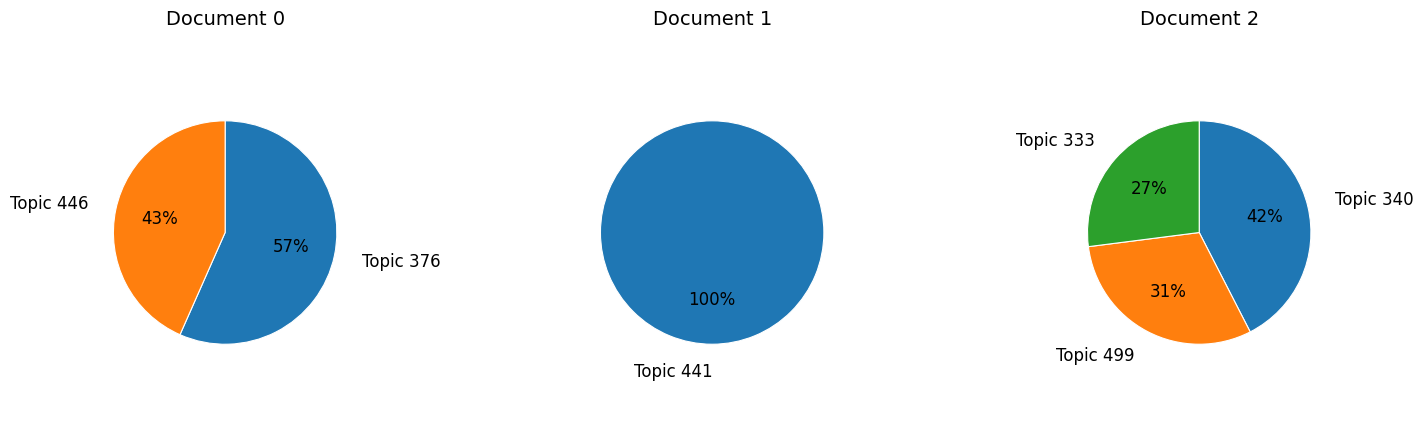

In [654]:
display_documents_grid(
    doc_ids=list(range(3)),
    final_topics_for_all=final_topics_for_all,
    top_k=4,
    ncols=3
)

In [592]:
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt

# Dataset Reuters
df = pd.read_csv("data/processed/csv/reuters_text.csv")

# Topic assegnati da PolyTopic
# Carica il pickle solo se il file proviene
# da una fonte attendibile.
with open("saved/reuters_bertopic/reuters_final_topics.pkl", "rb") as f:
    final_topics_for_all = pickle.load(f)

print("Number of documents:", len(df))
print("Number of topic assignments:", len(final_topics_for_all))

print("\nFirst document:")
print(df["text"].iloc[0][:300])

print("\nAssigned topics:")
print(final_topics_for_all[0])

Number of documents: 10252
Number of topic assignments: 10252

First document:
Showers continued throughout the week in the Bahia cocoa zone, alleviating the drought since early January and improving prospects for the coming temporao, although normal humidity levels have not been restored, Comissaria Smith said in its weekly review. The dry period means the temporao will be la

Assigned topics:
[(np.int64(53), np.float64(0.024370037917817635)), (np.int64(111), np.float64(0.02148584172121984))]


In [593]:
N_DOCUMENTS = 100
RANDOM_STATE = 42

rng = np.random.default_rng(RANDOM_STATE)

doc_ids = rng.choice(
    len(df),
    size=min(N_DOCUMENTS, len(df)),
    replace=False
)

# Testi selezionati
texts = df["text"].iloc[doc_ids].fillna("").tolist()

# Assegnazioni PolyTopic corrispondenti
selected_topics = [
    final_topics_for_all[int(doc_id)]
    for doc_id in doc_ids
]

In [594]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE

In [595]:
tfidf = TfidfVectorizer(
    max_features=10000,
    min_df=3,
    max_df=0.95,
    stop_words="english"
)

X_tfidf = tfidf.fit_transform(texts)

print(X_tfidf.shape)

(100, 517)


In [596]:
svd = TruncatedSVD(
    n_components=50,
    random_state=42
)

X_reduced = svd.fit_transform(X_tfidf)

print(X_reduced.shape)

(100, 50)


In [597]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=42
)

tsne_coords = tsne.fit_transform(X_reduced)

print(tsne_coords.shape)

(100, 2)


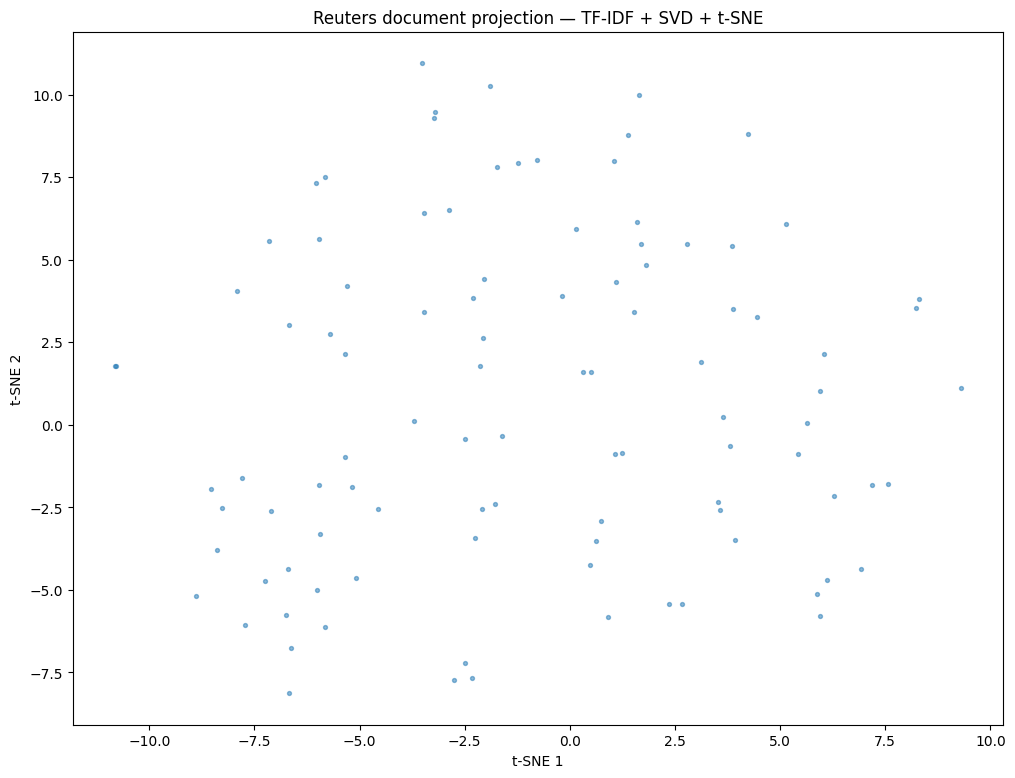

In [598]:
plt.figure(figsize=(12, 9))

plt.scatter(
    tsne_coords[:, 0],
    tsne_coords[:, 1],
    s=8,
    alpha=0.5
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Reuters document projection — TF-IDF + SVD + t-SNE")

plt.show()

In [599]:
# Tutti gli ID dei topic presenti
topic_ids = sorted({
    int(topic_id)
    for doc_topics in final_topics_for_all
    for topic_id, weight in doc_topics
})

topic_to_col = {
    topic_id: i
    for i, topic_id in enumerate(topic_ids)
}

X_topics = np.zeros(
    (len(final_topics_for_all), len(topic_ids)),
    dtype=np.float32
)

for doc_id, doc_topics in enumerate(final_topics_for_all):

    for topic_id, weight in doc_topics:

        X_topics[
            doc_id,
            topic_to_col[int(topic_id)]
        ] = float(weight)

print(X_topics.shape)

(10252, 129)


In [600]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=42
)

topic_tsne_coords = tsne.fit_transform(X_topics)

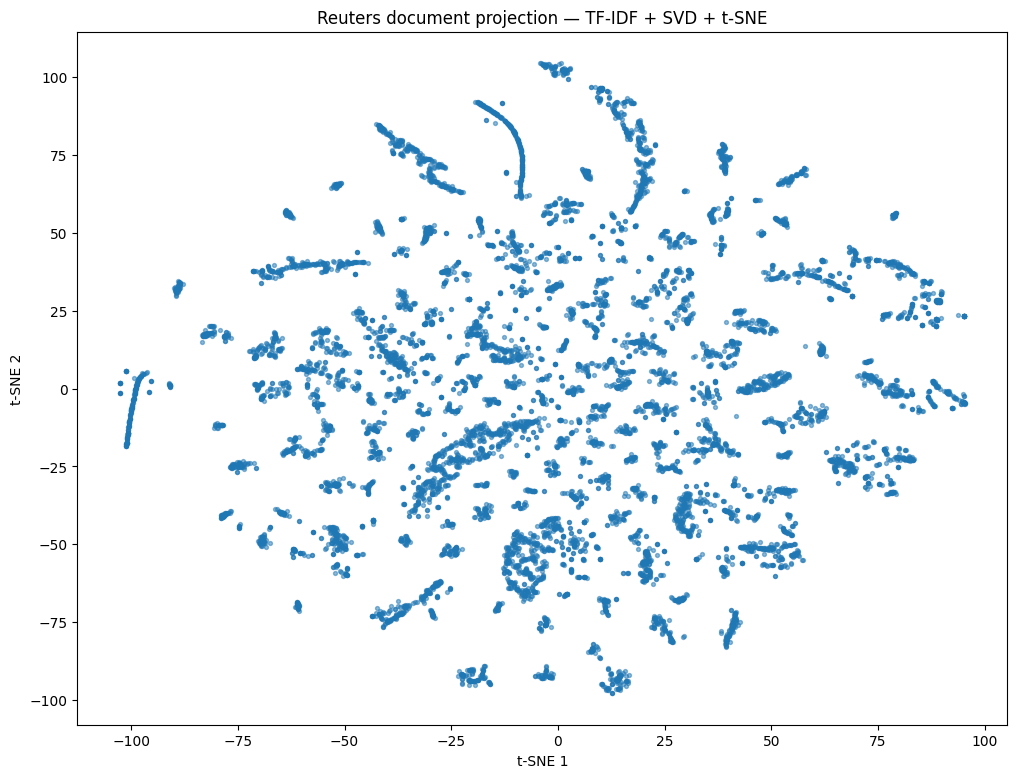

In [601]:
plt.figure(figsize=(12, 9))

plt.scatter(
    topic_tsne_coords[:, 0],
    topic_tsne_coords[:, 1],
    s=8,
    alpha=0.5
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Reuters document projection — TF-IDF + SVD + t-SNE")

plt.show()

In [608]:
# Step 1 — Caricamento dei dati


df = pd.read_csv("data/processed/csv/reuters_text.csv")

# Topic assegnati da PolyTopic
# Carica il pickle solo se il file proviene
# da una fonte attendibile.
with open("saved/reuters_bertopic/reuters_final_topics.pkl", "rb") as f:
    final_topics_for_all = pickle.load(f)

In [609]:
from collections import Counter
from itertools import combinations
import pandas as pd


def most_common_topic_groups(
    final_topics_for_all,
    group_size=2,
    top_n=20,
    min_weight=None
):
    """
    Conta in quanti documenti ciascun gruppo di topic
    compare contemporaneamente.

    group_size:
        2 -> coppie
        3 -> triple
        4 -> quadruple
    """

    counter = Counter()

    for doc_topics in final_topics_for_all:

        # Topic presenti nel documento
        topic_ids = []

        for topic_id, weight in doc_topics:

            if min_weight is None or float(weight) >= min_weight:
                topic_ids.append(int(topic_id))

        # Evita eventuali duplicati
        topic_ids = sorted(set(topic_ids))

        # Tutte le combinazioni di dimensione group_size
        for group in combinations(topic_ids, group_size):
            counter[group] += 1

    results = pd.DataFrame(
        counter.most_common(top_n),
        columns=["topics", "n_documents"]
    )

    return results

In [610]:
top_pairs = most_common_topic_groups(
    final_topics_for_all,
    group_size=2,
    top_n=30
)

top_pairs

,topics,n_documents
0,"(51, 111)",1009
1,"(105, 111)",651
2,"(0, 83)",487
3,"(0, 127)",487
4,"(83, 127)",450
5,"(2, 62)",426
6,"(109, 111)",344
7,"(0, 7)",306
8,"(7, 83)",298
9,"(7, 127)",293


In [611]:
top_triples = most_common_topic_groups(
    final_topics_for_all,
    group_size=3,
    top_n=30
)

top_triples

,topics,n_documents
0,"(0, 83, 127)",449
1,"(0, 7, 83)",298
2,"(0, 7, 127)",292
3,"(7, 83, 127)",290
4,"(51, 81, 111)",165
5,"(51, 105, 111)",103
6,"(51, 81, 105)",78
7,"(8, 78, 83)",73
8,"(81, 105, 111)",70
9,"(30, 65, 112)",45


In [612]:
top_quads = most_common_topic_groups(
    final_topics_for_all,
    group_size=4,
    top_n=30
)

top_quads

,topics,n_documents
0,"(0, 7, 83, 127)",290
1,"(51, 81, 105, 111)",69
2,"(0, 58, 83, 127)",19
3,"(0, 78, 83, 127)",18
4,"(0, 7, 58, 83)",18
5,"(0, 7, 58, 127)",18
6,"(7, 58, 83, 127)",18
7,"(0, 83, 124, 127)",16
8,"(51, 63, 81, 111)",14
9,"(102, 108, 109, 111)",13


In [613]:
# Parametri dell’esperimento

REFERENCE_TOPICS = [8, 58, 83, 124]

N_DOCS = 10252
RANDOM_STATE = 42

# Se True, nel pie compare anche una fetta
# che raggruppa tutti i topic non di riferimento
INCLUDE_OTHER = True

In [614]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


assert len(df) == len(final_topics_for_all)

print("Documents:", len(df))
print("Topic assignments:", len(final_topics_for_all))

Documents: 10252
Topic assignments: 10252


In [615]:
# 3. Selezione dei documenti

def select_documents_by_topics(
    final_topics_for_all,
    reference_topics,
    n_docs=None,
    random_state=42
):
    reference_topics = set(reference_topics)

    eligible_ids = []

    for doc_id, doc_topics in enumerate(final_topics_for_all):

        assigned_ids = {
            int(topic_id)
            for topic_id, weight in doc_topics
        }

        if assigned_ids.intersection(reference_topics):
            eligible_ids.append(doc_id)

    eligible_ids = np.array(eligible_ids)

    print(
        f"Documents containing at least one reference topic: "
        f"{len(eligible_ids)}"
    )

    if n_docs is not None and len(eligible_ids) > n_docs:

        rng = np.random.default_rng(random_state)

        selected_ids = rng.choice(
            eligible_ids,
            size=n_docs,
            replace=False
        )

    else:
        selected_ids = eligible_ids

    return np.sort(selected_ids)

In [616]:
selected_ids = select_documents_by_topics(
    final_topics_for_all,
    reference_topics=REFERENCE_TOPICS,
    n_docs=N_DOCS,
    random_state=RANDOM_STATE
)

print("Selected:", len(selected_ids))

Documents containing at least one reference topic: 1117
Selected: 1117


In [617]:
# 4. Controllare quanti documenti appartengono a ciascun topic

def topic_counts(
    final_topics_for_all,
    doc_ids,
    reference_topics
):
    counts = {
        topic: 0
        for topic in reference_topics
    }

    for doc_id in doc_ids:

        assigned = {
            int(topic_id)
            for topic_id, weight
            in final_topics_for_all[doc_id]
        }

        for topic in reference_topics:
            if topic in assigned:
                counts[topic] += 1

    return counts


counts = topic_counts(
    final_topics_for_all,
    selected_ids,
    REFERENCE_TOPICS
)



In [618]:
# Metodo A — TF-IDF + SVD + t-SNEcounts

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE

selected_texts = (
    df.loc[selected_ids, "text"]
    .fillna("")
    .astype(str)
    .tolist()
)

tfidf = TfidfVectorizer(
    max_features=10000,
    min_df=2,
    max_df=0.95,
    stop_words="english"
)

X_tfidf = tfidf.fit_transform(selected_texts)

print(X_tfidf.shape)

n_components = min(
    50,
    X_tfidf.shape[0] - 1,
    X_tfidf.shape[1] - 1
)

svd = TruncatedSVD(
    n_components=n_components,
    random_state=RANDOM_STATE
)

X_text_reduced = svd.fit_transform(X_tfidf)

tsne_text = TSNE(
    n_components=2,
    perplexity=min(30, (len(selected_ids) - 1) / 3),
    learning_rate="auto",
    init="pca",
    random_state=RANDOM_STATE
)

coords_text = tsne_text.fit_transform(
    X_text_reduced
)

(1117, 2104)


In [619]:
# Metodo B — topic vectors + t-SNE

def build_topic_matrix(
    final_topics_for_all,
    doc_ids
):
    # Tutti i topic esistenti nel dataset
    all_topic_ids = sorted({
        int(topic_id)
        for doc_topics in final_topics_for_all
        for topic_id, weight in doc_topics
    })

    topic_to_col = {
        topic_id: i
        for i, topic_id in enumerate(all_topic_ids)
    }

    X = np.zeros(
        (len(doc_ids), len(all_topic_ids)),
        dtype=np.float32
    )

    for row, doc_id in enumerate(doc_ids):

        for topic_id, weight in final_topics_for_all[doc_id]:

            X[
                row,
                topic_to_col[int(topic_id)]
            ] = float(weight)

    return X, all_topic_ids



In [620]:
X_topics, all_topic_ids = build_topic_matrix(
    final_topics_for_all,
    selected_ids
)

print(X_topics.shape)

(1117, 129)


In [588]:
tsne_topics = TSNE(
    n_components=2,
    perplexity=min(30, (len(selected_ids) - 1) / 3),
    learning_rate="auto",
    init="pca",
    random_state=RANDOM_STATE
)

coords_topics = tsne_topics.fit_transform(
    X_topics
)

In [621]:
from matplotlib.offsetbox import AnnotationBbox, DrawingArea
from matplotlib.patches import Wedge, Patch


def plot_reference_topic_pies(
    coords,
    doc_ids,
    final_topics_for_all,
    reference_topics,
    pie_size=16,
    include_other=True,
    figsize=(18, 10),
    title=None
):

    reference_topics = list(reference_topics)

    # stesso colore = stesso topic in tutti i documenti
    cmap = plt.cm.tab10

    topic_colors = {
        topic_id: cmap(i)
        for i, topic_id in enumerate(reference_topics)
    }

    other_color = (0.7, 0.7, 0.7, 1)

    fig, ax = plt.subplots(figsize=figsize)

    for point_index, doc_id in enumerate(doc_ids):

        doc_topics = final_topics_for_all[doc_id]

        topic_weights = {
            int(topic_id): float(weight)
            for topic_id, weight in doc_topics
        }

        values = []
        colors = []

        # Reference topics
        for topic_id in reference_topics:

            weight = topic_weights.get(topic_id, 0)

            if weight > 0:
                values.append(weight)
                colors.append(
                    topic_colors[topic_id]
                )

        # Tutti gli altri topic
        if include_other:

            other_weight = sum(
                weight
                for topic_id, weight in topic_weights.items()
                if topic_id not in reference_topics
            )

            if other_weight > 0:
                values.append(other_weight)
                colors.append(other_color)

        if len(values) == 0:
            continue

        values = np.array(
            values,
            dtype=float
        )

        values /= values.sum()

        da = DrawingArea(
            pie_size,
            pie_size,
            0,
            0
        )

        center = (
            pie_size / 2,
            pie_size / 2
        )

        radius = pie_size / 2

        start_angle = 90

        for value, color in zip(values, colors):

            end_angle = (
                start_angle
                + value * 360
            )

            wedge = Wedge(
                center,
                radius,
                start_angle,
                end_angle,
                facecolor=color,
                edgecolor="white",
                linewidth=0.35
            )

            da.add_artist(wedge)

            start_angle = end_angle

        marker = AnnotationBbox(
            da,
            coords[point_index],
            frameon=False,
            pad=0,
            box_alignment=(0.5, 0.5)
        )

        ax.add_artist(marker)

    # limiti
    margin_x = (
        coords[:, 0].max()
        - coords[:, 0].min()
    ) * 0.05

    margin_y = (
        coords[:, 1].max()
        - coords[:, 1].min()
    ) * 0.05

    ax.set_xlim(
        coords[:, 0].min() - margin_x,
        coords[:, 0].max() + margin_x
    )

    ax.set_ylim(
        coords[:, 1].min() - margin_y,
        coords[:, 1].max() + margin_y
    )

    # legenda
    handles = [
        Patch(
            facecolor=topic_colors[topic_id],
            label=f"Topic {topic_id}"
        )
        for topic_id in reference_topics
    ]

    if include_other:
        handles.append(
            Patch(
                facecolor=other_color,
                label="Other assigned topics"
            )
        )

    ax.legend(
        handles=handles,
        bbox_to_anchor=(0.82, 1),
        loc="upper left",
        fontsize=14
    )

    # ax.set_xlabel("t-SNE 1")
    # ax.set_ylabel("t-SNE 2")

    if title is not None:
        ax.set_title(title)

    plt.tight_layout()
    plt.savefig(
        f"doc_svd_{str(reference_topics)}.pdf",
        format="pdf",
        bbox_inches="tight",
        pad_inches=0
    )

    plt.show()

In [622]:
reference_set = set(REFERENCE_TOPICS)

all_eligible_ids = [
    doc_id
    for doc_id, doc_topics in enumerate(final_topics_for_all)
    if any(
        int(topic_id) in reference_set
        for topic_id, weight in doc_topics
    )
]

print("Eligible documents:", len(all_eligible_ids))
print("Plotted documents:", len(selected_ids))

Eligible documents: 1117
Plotted documents: 1117


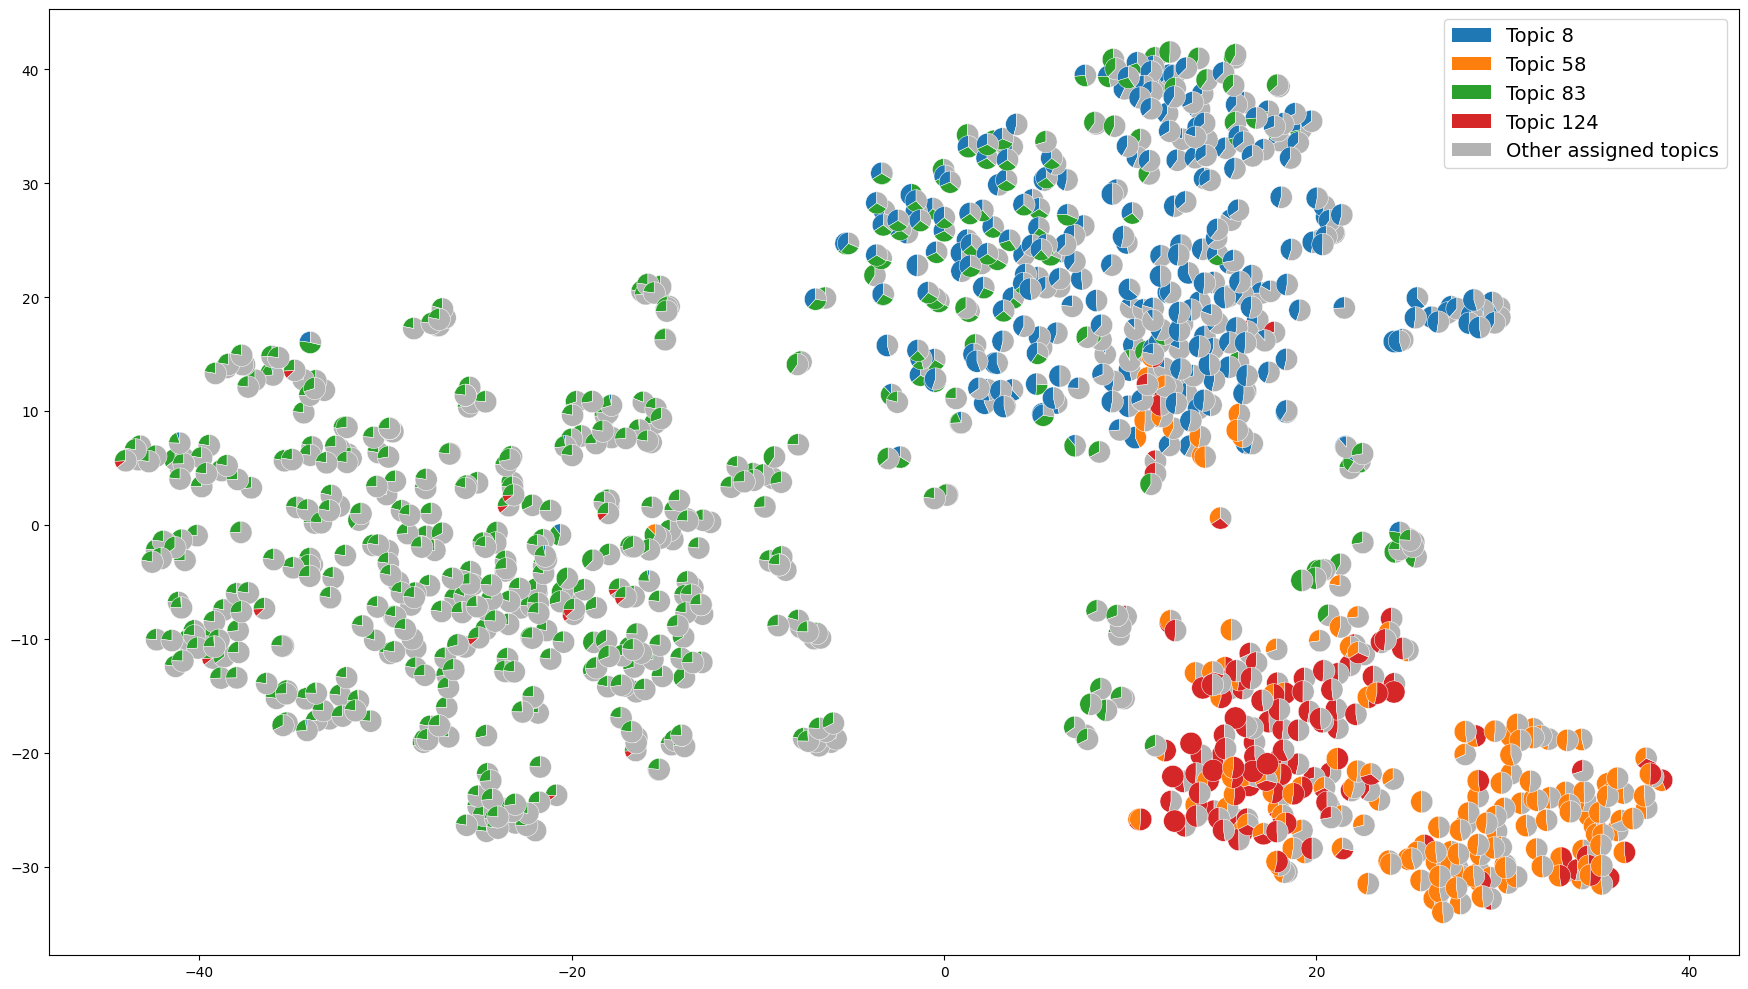

In [623]:
# plot based on text: document with similar lexical content are close to each other in the 2D space

plot_reference_topic_pies(
    coords=coords_text,
    doc_ids=selected_ids,
    final_topics_for_all=final_topics_for_all,
    reference_topics=REFERENCE_TOPICS,
    pie_size=16,
    include_other=True,
    # title=(
    #     "Reuters — TF-IDF + SVD + t-SNE "
    #     "with PolyTopic assignments"
    # )
)

In [489]:
# # plot based on topic assignment: documents with similar topic assignments are close to each other in the 2D space

# plot_reference_topic_pies(
#     coords=coords_topics,
#     doc_ids=selected_ids,
#     final_topics_for_all=final_topics_for_all,
#     reference_topics=REFERENCE_TOPICS,
#     pie_size=16,
#     include_other=True,
#     # title=(
#     #     "Reuters — Topic-assignment t-SNE "
#     #     "with PolyTopic assignments"
#     # )
# )